In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
# Cell 1: Install dependencies and verify rlemasklib works
# pycocotools is NOT used anywhere in this notebook.

!pip uninstall -y pycocotools
!pip install -q rlemasklib
!pip install -q fastlabelrle
!pip install -q segmentation-models-pytorch==0.3.4
!pip install -q "albumentations==1.4.14" "albucore==0.0.14"

# Verification
import numpy as np
from rlemasklib import RLEMask

test = np.zeros((10, 10), dtype=np.uint8)
test[2:5, 2:5] = 1

rle_dict = RLEMask(test).to_dict()
print("RLE dict keys:", rle_dict.keys())
print("Size:", rle_dict["size"])

decoded = RLEMask.from_dict(rle_dict).to_array()
assert decoded.sum() == 9, f"Decode failed: expected 9, got {decoded.sum()}"
assert decoded.shape == (10, 10), f"Shape mismatch: {decoded.shape}"

print("PASS: rlemasklib encode/decode works")
print("Restart kernel before running Cell 2.")

In [1]:
# Cell 2: Imports and path setup
import os
import json
import random
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from rlemasklib import RLEMask
from fastlabelrle import encode as fast_rle_encode
from tqdm import tqdm
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Paths (exactly as provided)
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TEST_IMAGES = ROOT / "test" / "test_images"

OUTPUT_DIR = Path("/kaggle/working")
WEIGHTS_DIR = OUTPUT_DIR / "weights"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"Train JPEGs: {len(list(TRAIN_IMAGES.glob('*.jpeg')))}")
print(f"Test JPEGs: {len(list(TEST_IMAGES.glob('*.jpeg')))}")
print(f"Train JSON exists: {TRAIN_JSON.exists()}")

/usr/local/lib/python3.13/dist-packages/albumentations/__init__.py:13: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.14). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


Device: cuda
Train JPEGs: 707
Test JPEGs: 180
Train JSON exists: True


In [29]:
# Cell B: Load JSON and build fast lookup structures
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

img_id_to_info = {img["id"]: img for img in coco["images"]}
anns_by_image  = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

file_to_ids = defaultdict(list)
for img in coco["images"]:
    file_to_ids[img["file_name"]].append(img["id"])

summary = {
    "image_records":   len(coco["images"]),
    "annotations":     len(coco["annotations"]),
    "unique_files":    len(file_to_ids),
    "annotated_ids":   len(anns_by_image),
    "categories":      [c["name"] for c in coco.get("categories", [])],
    "image_size":      (coco["images"][0]["height"], coco["images"][0]["width"]),
}
for k, v in summary.items():
    print(f"{k}: {v}")

image_records: 1154
annotations: 8199
unique_files: 707
annotated_ids: 1154
categories: ['Left', 'Right', 'Unidentifiable', 'Ambiguous']
image_size: (2048, 2048)


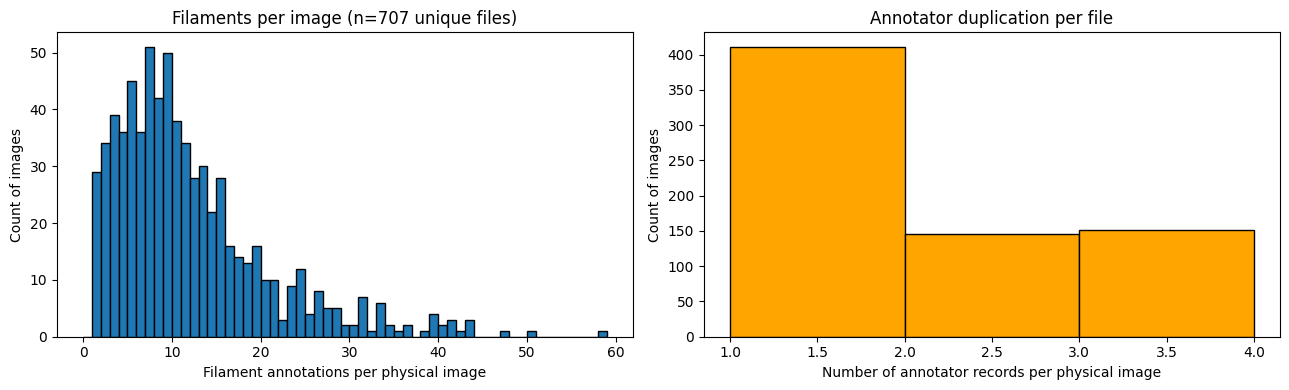

Figure saved: /kaggle/working/eda/C_annotation_counts.png
Annotations/image: min=1, median=9, max=58
Files annotated by >1 annotator: 296 / 707


In [41]:
# Cell C (self-contained): Annotations per image + annotator duplication.
# Rebuilds every variable this cell needs so it runs in any kernel state.

import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON   = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TEST_IMAGES  = ROOT / "test" / "test_images"

OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Load annotations and rebuild indexes ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

img_id_to_info = {img["id"]: img for img in coco["images"]}
anns_by_image  = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

file_to_ids = defaultdict(list)
for img in coco["images"]:
    file_to_ids[img["file_name"]].append(img["id"])

# --- Compute the two histograms ---
anns_per_physical   = [sum(len(anns_by_image[i]) for i in ids) for ids in file_to_ids.values()]
annotators_per_file = [len(ids) for ids in file_to_ids.values()]

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(anns_per_physical, bins=range(0, max(anns_per_physical) + 2), edgecolor="black")
axes[0].set_xlabel("Filament annotations per physical image")
axes[0].set_ylabel("Count of images")
axes[0].set_title(f"Filaments per image (n={len(anns_per_physical)} unique files)")

axes[1].hist(annotators_per_file, bins=range(1, max(annotators_per_file) + 2),
             edgecolor="black", color="orange")
axes[1].set_xlabel("Number of annotator records per physical image")
axes[1].set_ylabel("Count of images")
axes[1].set_title("Annotator duplication per file")

plt.tight_layout()
save_path = OUT / "C_annotation_counts.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")

# --- Numbers ---
print(f"Annotations/image: min={min(anns_per_physical)}, "
      f"median={int(np.median(anns_per_physical))}, max={max(anns_per_physical)}")
print(f"Files annotated by >1 annotator: "
      f"{sum(1 for c in annotators_per_file if c > 1)} / {len(annotators_per_file)}")

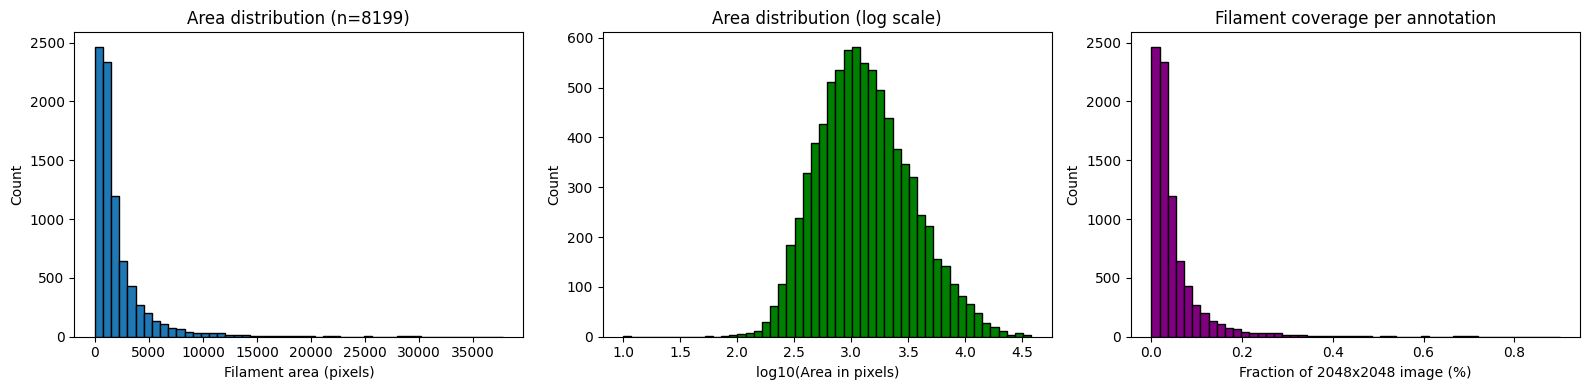

Figure saved: /kaggle/working/eda/D_area_distribution.png
Area (px):  min=9, median=1228, mean=2120, max=37739
Coverage:   min=0.0002%, median=0.0293%, max=0.8998%
Total filament pixels in dataset: 17,380,527.0


In [42]:
# Cell D (self-contained): Area distribution of filaments.
# Rebuilds OUT, coco, and the data paths so it runs in any kernel state.

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_JSON = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Load annotations ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

# --- Compute areas ---
areas_px = np.array([a["area"] for a in coco["annotations"]])
img_area = 2048 * 2048
areas_frac = areas_px / img_area

# --- Plot ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(areas_px, bins=50, edgecolor="black")
axes[0].set_xlabel("Filament area (pixels)")
axes[0].set_ylabel("Count")
axes[0].set_title(f"Area distribution (n={len(areas_px)})")

axes[1].hist(np.log10(areas_px + 1), bins=50, edgecolor="black", color="green")
axes[1].set_xlabel("log10(Area in pixels)")
axes[1].set_ylabel("Count")
axes[1].set_title("Area distribution (log scale)")

axes[2].hist(areas_frac * 100, bins=50, edgecolor="black", color="purple")
axes[2].set_xlabel("Fraction of 2048x2048 image (%)")
axes[2].set_ylabel("Count")
axes[2].set_title("Filament coverage per annotation")

plt.tight_layout()
save_path = OUT / "D_area_distribution.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")

# --- Numbers ---
print(f"Area (px):  min={areas_px.min():.0f}, median={np.median(areas_px):.0f}, "
      f"mean={areas_px.mean():.0f}, max={areas_px.max():.0f}")
print(f"Coverage:   min={areas_frac.min()*100:.4f}%, median={np.median(areas_frac)*100:.4f}%, "
      f"max={areas_frac.max()*100:.4f}%")
print(f"Total filament pixels in dataset: {areas_px.sum():,}")

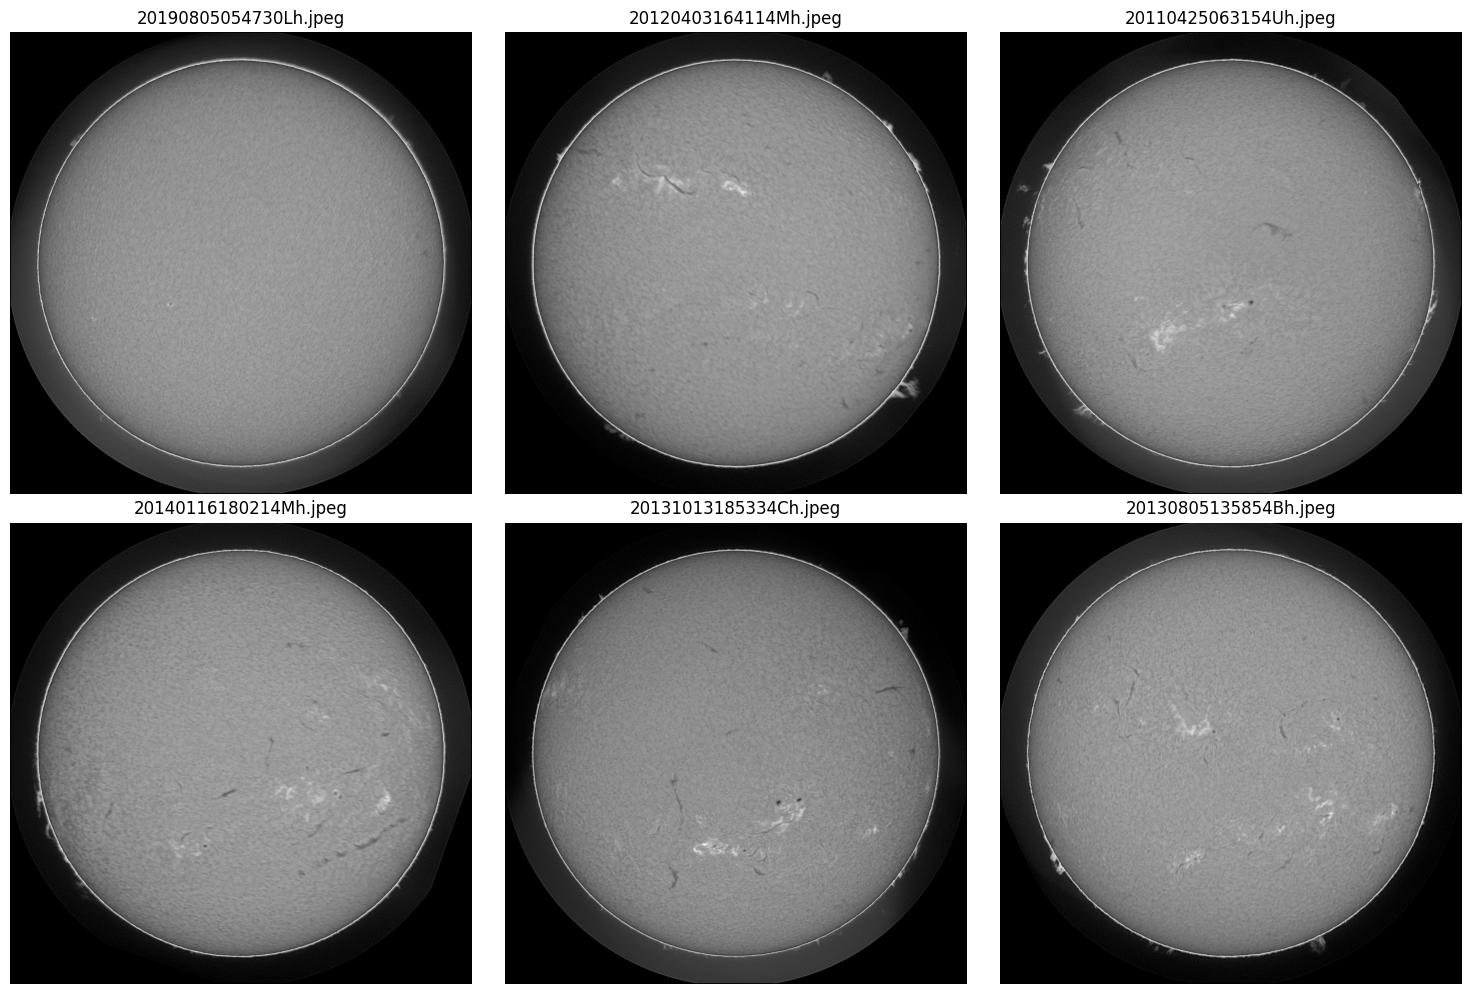

Figure saved: /kaggle/working/eda/E_raw_train_samples.png


In [43]:
# Cell E (self-contained): Six random raw training images.
# Rebuilds every variable this cell needs — runs in any kernel state.

import json
import random
from pathlib import Path
from collections import defaultdict

import cv2
import matplotlib.pyplot as plt

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON   = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Rebuild file index ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

file_to_ids = defaultdict(list)
for img in coco["images"]:
    file_to_ids[img["file_name"]].append(img["id"])

# --- Sample and plot ---
random.seed(42)
sample_files = random.sample(sorted(file_to_ids.keys()), 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, fname in zip(axes.flat, sample_files):
    img = cv2.imread(str(TRAIN_IMAGES / fname), cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(fname)
    ax.axis("off")

plt.tight_layout()
save_path = OUT / "E_raw_train_samples.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")

Files with annotations: 707 / 707


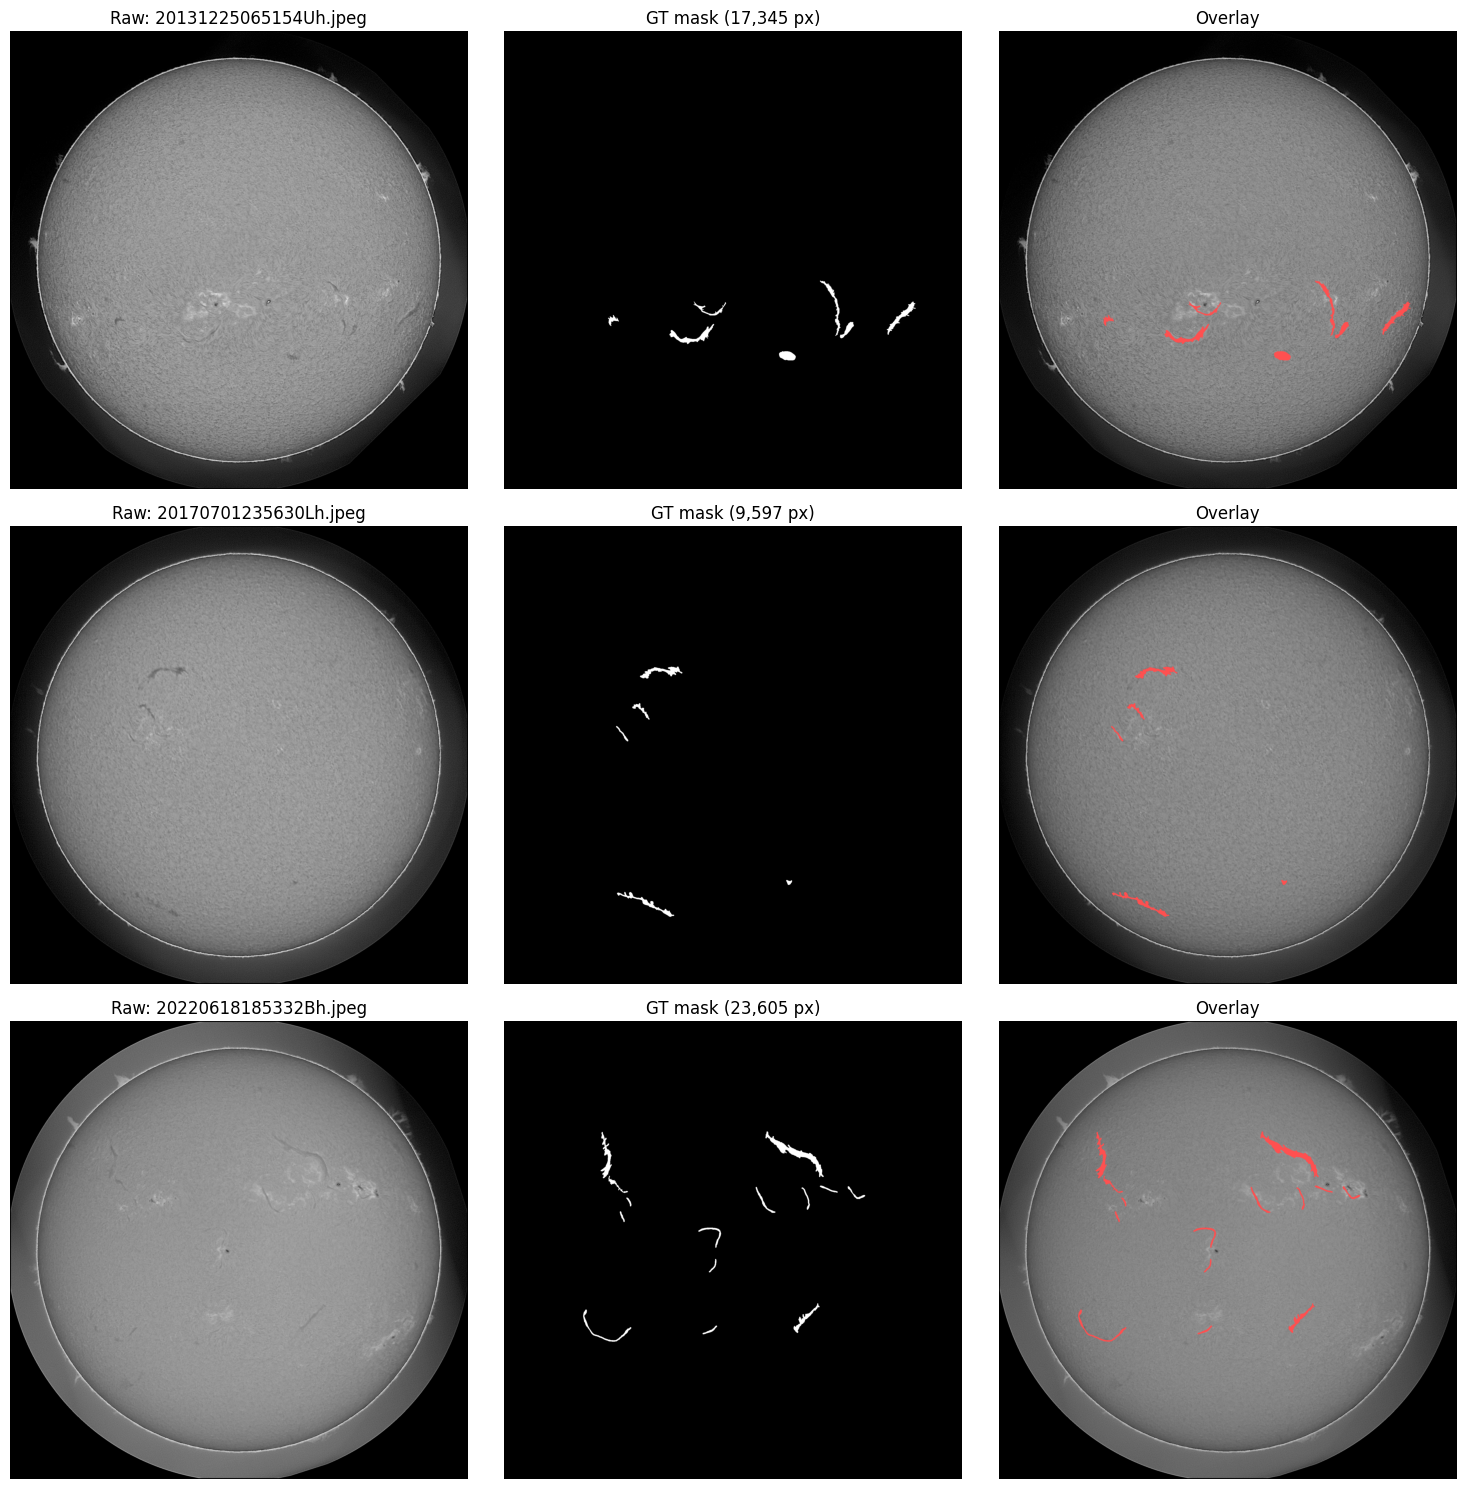

Figure saved: /kaggle/working/eda/F_train_with_masks.png


In [44]:
# Cell F (self-contained): Raw image + ground-truth mask overlay for 3 files.
# Fixes the unhashable-list bug by checking membership with any(...).

import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt
from rlemasklib import RLEMask

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON   = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Rebuild indexes ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

img_id_to_info = {img["id"]: img for img in coco["images"]}
anns_by_image  = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

file_to_ids = defaultdict(list)
for img in coco["images"]:
    file_to_ids[img["file_name"]].append(img["id"])

# --- Pick files that actually have annotations ---
# The fix: check if ANY of the file's image_ids is in anns_by_image.
files_with_annotations = [
    f for f in file_to_ids if any(iid in anns_by_image for iid in file_to_ids[f])
]
print(f"Files with annotations: {len(files_with_annotations)} / {len(file_to_ids)}")

random.seed(42)
sample_files = random.sample(files_with_annotations, 3)

# --- Plot 3 rows x 3 columns: raw / mask / overlay ---
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for r, fname in enumerate(sample_files):
    ids = file_to_ids[fname]
    img = cv2.imread(str(TRAIN_IMAGES / fname), cv2.IMREAD_GRAYSCALE)
    H, W = img.shape

    gt = np.zeros((H, W), dtype=np.uint8)
    for iid in ids:
        for ann in anns_by_image.get(iid, []):
            seg = ann["segmentation"][0]
            m = RLEMask.from_polygon(np.array(seg).reshape(-1, 2), imshape=(H, W)).to_array()
            gt = np.maximum(gt, m.astype(np.uint8))

    axes[r, 0].imshow(img, cmap="gray")
    axes[r, 0].set_title(f"Raw: {fname}")
    axes[r, 0].axis("off")

    axes[r, 1].imshow(gt, cmap="gray")
    axes[r, 1].set_title(f"GT mask ({gt.sum():,} px)")
    axes[r, 1].axis("off")

    overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    overlay[gt.astype(bool)] = [255, 80, 80]
    axes[r, 2].imshow(overlay)
    axes[r, 2].set_title("Overlay")
    axes[r, 2].axis("off")

plt.tight_layout()
save_path = OUT / "F_train_with_masks.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")

Files with multiple annotators: 296


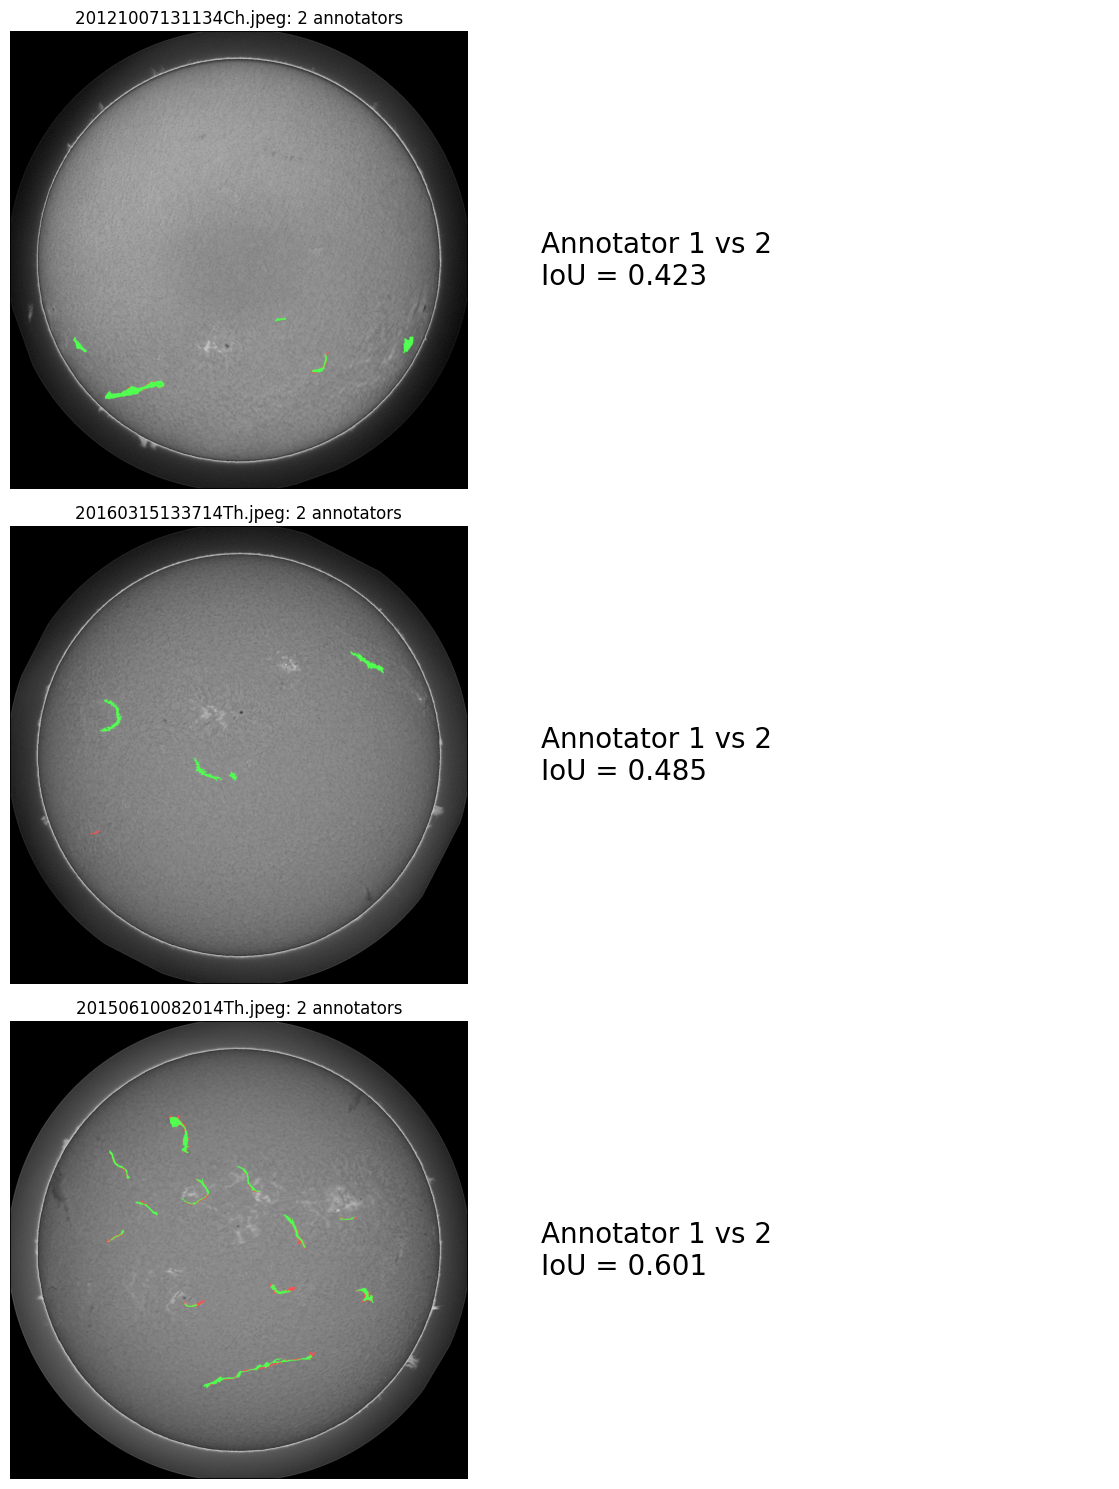

Figure saved: /kaggle/working/eda/G_annotator_disagreement.png


In [45]:
# Cell G (self-contained): Annotator disagreement on duplicate files.
# Rebuilds every variable this cell needs and fixes the unhashable-list pattern.

import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt
from rlemasklib import RLEMask

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON   = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Rebuild indexes ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

anns_by_image = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

file_to_ids = defaultdict(list)
for img in coco["images"]:
    file_to_ids[img["file_name"]].append(img["id"])

# --- Files annotated by more than one annotator ---
duplicates = {f: ids for f, ids in file_to_ids.items() if len(ids) > 1}
print(f"Files with multiple annotators: {len(duplicates)}")

if duplicates:
    random.seed(42)
    sample = random.sample(list(duplicates.keys()), min(3, len(duplicates)))

    fig, axes = plt.subplots(len(sample), 2, figsize=(12, 5 * len(sample)))
    if len(sample) == 1:
        axes = np.array([axes])

    for r, fname in enumerate(sample):
        img = cv2.imread(str(TRAIN_IMAGES / fname), cv2.IMREAD_GRAYSCALE)
        H, W = img.shape

        masks = []
        for iid in duplicates[fname]:
            m = np.zeros((H, W), dtype=np.uint8)
            for ann in anns_by_image.get(iid, []):
                seg = ann["segmentation"][0]
                poly = RLEMask.from_polygon(
                    np.array(seg).reshape(-1, 2), imshape=(H, W)
                ).to_array()
                m = np.maximum(m, poly.astype(np.uint8))
            masks.append(m)

        # Overlay all annotators in distinct colors
        overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        colors = [[255, 80, 80], [80, 255, 80], [80, 80, 255],
                  [255, 255, 80], [255, 80, 255], [80, 255, 255]]
        for m, c in zip(masks, colors):
            overlay[m.astype(bool)] = c
        axes[r, 0].imshow(overlay)
        axes[r, 0].set_title(f"{fname}: {len(masks)} annotators")
        axes[r, 0].axis("off")

        # IoU between first two annotators, as a label-noise proxy
        if len(masks) >= 2:
            inter = np.logical_and(masks[0].astype(bool), masks[1].astype(bool)).sum()
            union = np.logical_or(masks[0].astype(bool), masks[1].astype(bool)).sum()
            iou = inter / union if union > 0 else 0.0
            axes[r, 1].text(0.05, 0.5,
                            f"Annotator 1 vs 2\nIoU = {iou:.3f}",
                            fontsize=20, ha="left", va="center")
            axes[r, 1].axis("off")

    plt.tight_layout()
    save_path = OUT / "G_annotator_disagreement.png"
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f"Figure saved: {save_path}")
else:
    print("No duplicate files found — all images annotated once.")

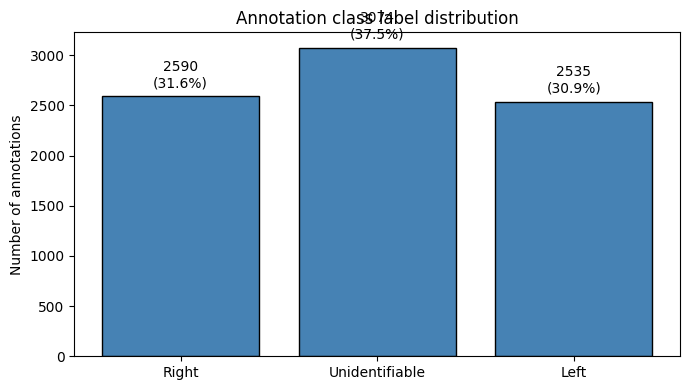

Figure saved: /kaggle/working/eda/H_class_labels.png
Counter({'Unidentifiable': 3074, 'Right': 2590, 'Left': 2535})


In [46]:
# Cell H (self-contained): Category label distribution.
# Fixes missing Counter import and rebuilds every dependency.

import json
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_JSON = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Load annotations ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

# --- Category distribution ---
cats = {c["id"]: c["name"] for c in coco.get("categories", [])}
label_counts = Counter(cats.get(a.get("category_id"), "Unknown")
                       for a in coco["annotations"])

# --- Plot ---
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(list(label_counts.keys()), list(label_counts.values()),
              color="steelblue", edgecolor="black")
ax.set_ylabel("Number of annotations")
ax.set_title("Annotation class label distribution")

max_v = max(label_counts.values()) if label_counts else 1
for bar, (k, v) in zip(bars, label_counts.items()):
    ax.text(bar.get_x() + bar.get_width() / 2, v + max_v * 0.02,
            f"{v}\n({100 * v / len(coco['annotations']):.1f}%)",
            ha="center", va="bottom", fontsize=10)

plt.tight_layout()
save_path = OUT / "H_class_labels.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")
print(label_counts)

Total test images: 180


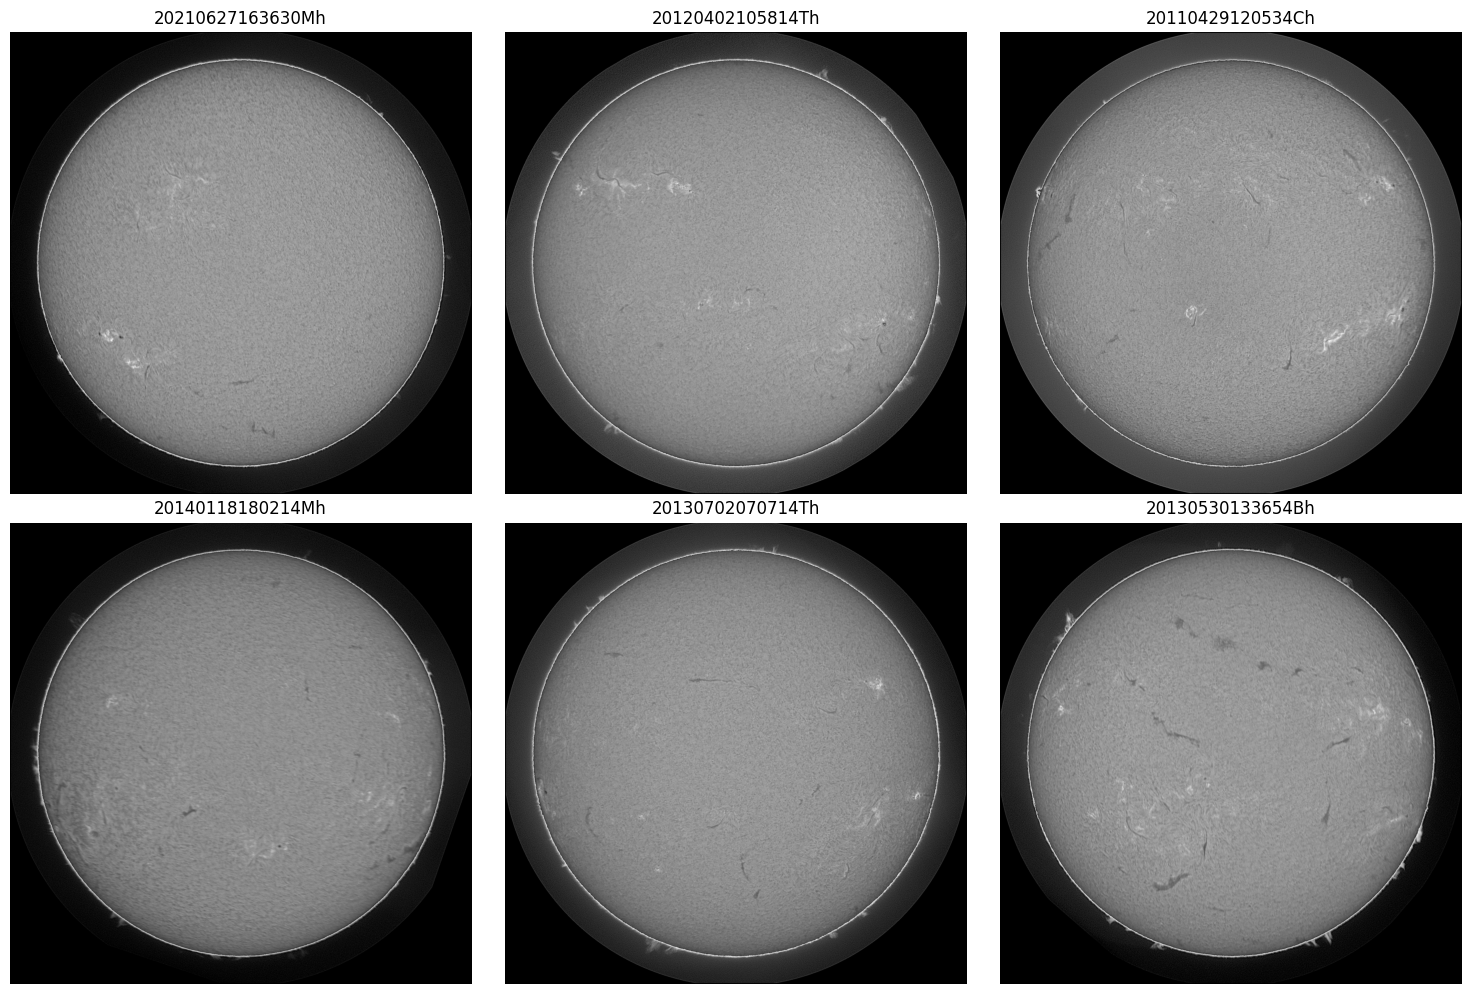

Figure saved: /kaggle/working/eda/I_raw_test_samples.png


In [47]:
# Cell I (self-contained): Six raw test images — what the model sees in submission mode.
# Rebuilds every variable this cell needs.

import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TEST_IMAGES = ROOT / "test" / "test_images"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Enumerate test files ---
test_files = sorted(TEST_IMAGES.glob("*.jpeg"))
print(f"Total test images: {len(test_files)}")

# --- Sample and plot ---
random.seed(42)
sample_tests = random.sample(test_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, p in zip(axes.flat, sample_tests):
    img = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(p.stem)
    ax.axis("off")

plt.tight_layout()
save_path = OUT / "I_raw_test_samples.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")

Train files: 707, Test files: 180


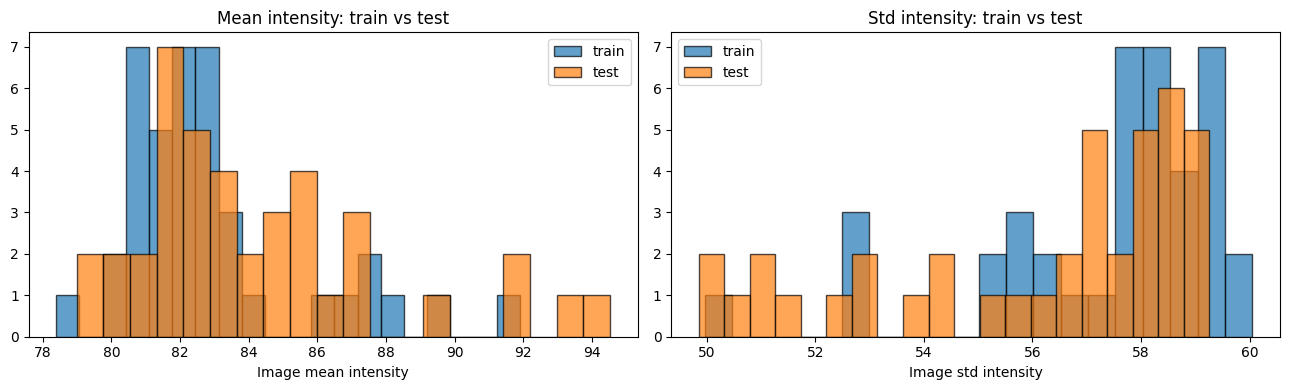

Figure saved: /kaggle/working/eda/J_intensity_train_vs_test.png

Train mean: 83.0 +/- 2.8
Test  mean: 84.3 +/- 3.7
Train std:  57.4 +/- 2.2
Test  std:  56.1 +/- 2.9
Train p1:   0.0, p99: 155.0
Test  p1:   0.0, p99: 154.1


In [48]:
# Cell J (self-contained): Train vs Test intensity distributions.
# Rebuilds every variable this cell needs.

import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON   = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TEST_IMAGES  = ROOT / "test" / "test_images"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Rebuild train file list ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)
file_to_ids = defaultdict(list)
for img in coco["images"]:
    file_to_ids[img["file_name"]].append(img["id"])

test_files = sorted(TEST_IMAGES.glob("*.jpeg"))
print(f"Train files: {len(file_to_ids)}, Test files: {len(test_files)}")

# --- Sample and compute intensity stats ---
def pixel_stats(paths, n=40):
    means, stds, p1, p99 = [], [], [], []
    for p in random.sample(paths, min(n, len(paths))):
        img = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        means.append(img.mean())
        stds.append(img.std())
        p1.append(np.percentile(img, 1))
        p99.append(np.percentile(img, 99))
    return np.array(means), np.array(stds), np.array(p1), np.array(p99)

random.seed(42)
tr_means, tr_stds, tr_p1, tr_p99 = pixel_stats([TRAIN_IMAGES / f for f in file_to_ids.keys()])
te_means, te_stds, te_p1, te_p99 = pixel_stats(test_files)

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(tr_means, bins=20, alpha=0.7, label="train", edgecolor="black")
axes[0].hist(te_means, bins=20, alpha=0.7, label="test", edgecolor="black")
axes[0].set_xlabel("Image mean intensity")
axes[0].legend()
axes[0].set_title("Mean intensity: train vs test")

axes[1].hist(tr_stds, bins=20, alpha=0.7, label="train", edgecolor="black")
axes[1].hist(te_stds, bins=20, alpha=0.7, label="test", edgecolor="black")
axes[1].set_xlabel("Image std intensity")
axes[1].legend()
axes[1].set_title("Std intensity: train vs test")

plt.tight_layout()
save_path = OUT / "J_intensity_train_vs_test.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")

# --- Numbers ---
print(f"\nTrain mean: {tr_means.mean():.1f} +/- {tr_means.std():.1f}")
print(f"Test  mean: {te_means.mean():.1f} +/- {te_means.std():.1f}")
print(f"Train std:  {tr_stds.mean():.1f} +/- {tr_stds.std():.1f}")
print(f"Test  std:  {te_stds.mean():.1f} +/- {te_stds.std():.1f}")
print(f"Train p1:   {tr_p1.mean():.1f}, p99: {tr_p99.mean():.1f}")
print(f"Test  p1:   {te_p1.mean():.1f}, p99: {te_p99.mean():.1f}")

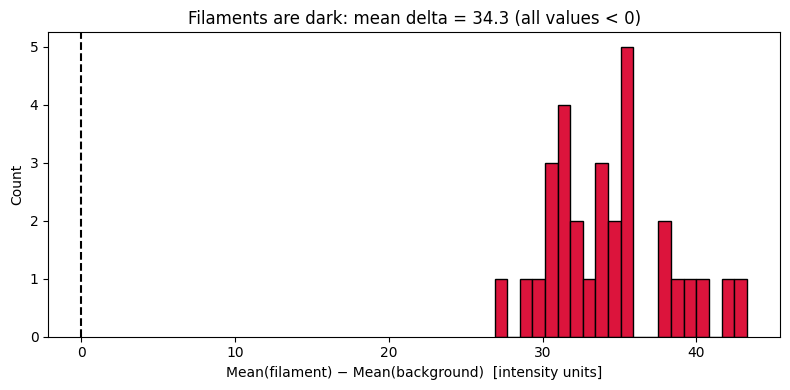

Filament − background intensity: mean = 34.30, min = 26.88, max = 43.28
Fraction of images where filaments are darker: 0.0%


In [52]:
# Cell K: Are filaments actually darker than the surrounding disk?
# This is the fundamental physics assumption behind the whole pipeline.
deltas = []
for iid in random.sample(list(anns_by_image.keys()), 30):
    info = img_id_to_info[iid]
    img = cv2.imread(str(TRAIN_IMAGES / info["file_name"]), cv2.IMREAD_GRAYSCALE)
    H, W = img.shape
    m = np.zeros((H, W), dtype=np.uint8)
    for ann in anns_by_image[iid]:
        seg = ann["segmentation"][0]
        poly = RLEMask.from_polygon(np.array(seg).reshape(-1, 2), imshape=(H, W)).to_array()
        m = np.maximum(m, poly.astype(np.uint8))
    if m.sum() == 0:
        continue
    fg_mean = img[m.astype(bool)].mean()
    bg_mean = img[~m.astype(bool)].mean()
    deltas.append(fg_mean - bg_mean)

deltas = np.array(deltas)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(deltas, bins=20, edgecolor="black", color="crimson")
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Mean(filament) − Mean(background)  [intensity units]")
ax.set_ylabel("Count")
ax.set_title(f"Filaments are dark: mean delta = {deltas.mean():.1f} (all values < 0)")
plt.tight_layout()
plt.savefig(OUT / "K_filament_brightness.png", dpi=150)
plt.show()

print(f"Filament − background intensity: mean = {deltas.mean():.2f}, "
      f"min = {deltas.min():.2f}, max = {deltas.max():.2f}")
print(f"Fraction of images where filaments are darker: {(deltas < 0).mean()*100:.1f}%")

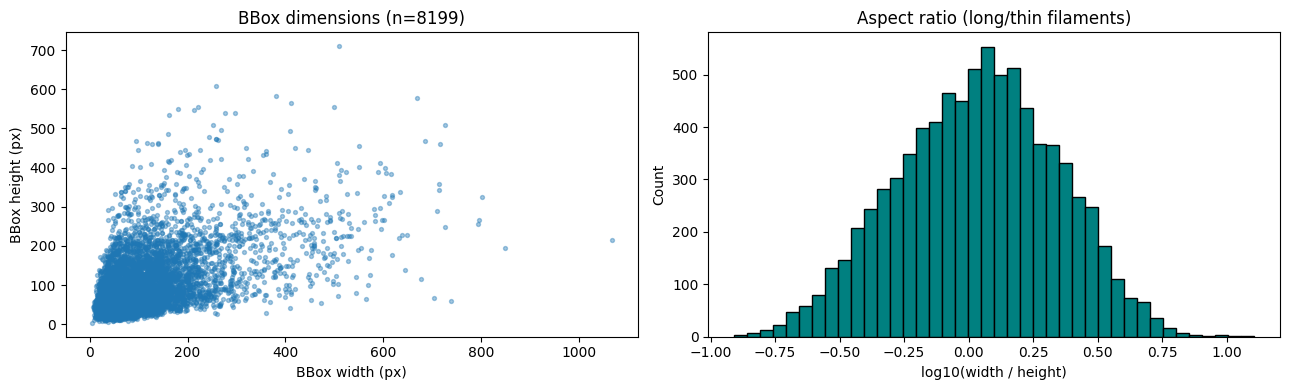

Figure saved: /kaggle/working/eda/L_bbox_aspect.png

BBox width (px):  min=4, median=75, max=1067
BBox height (px): min=3, median=70, max=710
Aspect ratio:     median=1.11, p10=0.41, p90=2.73
Fraction with aspect > 2 (elongated): 20.7%


In [53]:
# Cell L (self-contained): Filament bounding-box aspect ratio distribution.
# Rebuilds every variable this cell needs.

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_JSON = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

# --- Load annotations ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

# --- Compute bbox width, height, aspect ---
ws = np.array([a["bbox"][2] for a in coco["annotations"]])
hs = np.array([a["bbox"][3] for a in coco["annotations"]])
aspects = ws / np.maximum(hs, 1)

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(ws, hs, s=8, alpha=0.4)
axes[0].set_xlabel("BBox width (px)")
axes[0].set_ylabel("BBox height (px)")
axes[0].set_title(f"BBox dimensions (n={len(ws)})")

axes[1].hist(np.log10(aspects + 1e-3), bins=40, edgecolor="black", color="teal")
axes[1].set_xlabel("log10(width / height)")
axes[1].set_ylabel("Count")
axes[1].set_title("Aspect ratio (long/thin filaments)")

plt.tight_layout()
save_path = OUT / "L_bbox_aspect.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")

# --- Numbers ---
print(f"\nBBox width (px):  min={ws.min():.0f}, median={np.median(ws):.0f}, max={ws.max():.0f}")
print(f"BBox height (px): min={hs.min():.0f}, median={np.median(hs):.0f}, max={hs.max():.0f}")
print(f"Aspect ratio:     median={np.median(aspects):.2f}, "
      f"p10={np.percentile(aspects, 10):.2f}, "
      f"p90={np.percentile(aspects, 90):.2f}")
print(f"Fraction with aspect > 2 (elongated): {(aspects > 2).mean()*100:.1f}%")

Files with annotations: 707 / 707
Empty-crop fraction (uniform 512x512): 44.0%
This is the failure mode that collapsed the first training run.


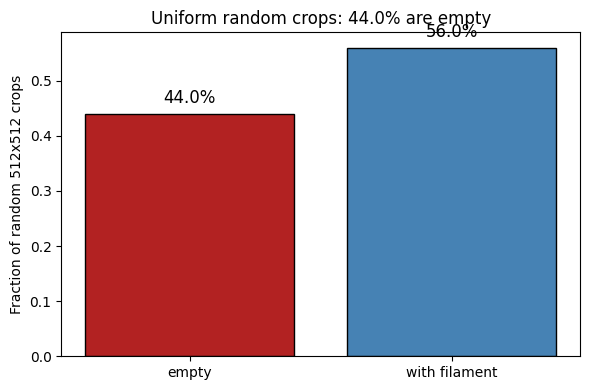

Figure saved: /kaggle/working/eda/M_empty_crop_fraction.png


In [54]:
# Cell M (self-contained): Empty-crop fraction under uniform 512x512 sampling.
# Fixes the unhashable-list bug and rebuilds every dependency.

import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt
from rlemasklib import RLEMask

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON   = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

random.seed(42); np.random.seed(42)

# --- Rebuild indexes ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

anns_by_image = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

file_to_ids = defaultdict(list)
for img in coco["images"]:
    file_to_ids[img["file_name"]].append(img["id"])

# --- Fix: check whether ANY annotator id for this file is in anns_by_image ---
files_with_ann = [
    f for f in file_to_ids if any(i in anns_by_image for i in file_to_ids[f])
]
print(f"Files with annotations: {len(files_with_ann)} / {len(file_to_ids)}")

# --- Sample random crops and count empty ones ---
def random_crop_empty_fraction(file_list, n_crops=200, crop=512):
    empties = 0
    for _ in range(n_crops):
        fname = random.choice(file_list)
        img = cv2.imread(str(TRAIN_IMAGES / fname), cv2.IMREAD_GRAYSCALE)
        H, W = img.shape
        m = np.zeros((H, W), dtype=np.uint8)
        for iid in file_to_ids[fname]:
            for ann in anns_by_image.get(iid, []):
                seg = ann["segmentation"][0]
                poly = RLEMask.from_polygon(
                    np.array(seg).reshape(-1, 2), imshape=(H, W)
                ).to_array()
                m = np.maximum(m, poly.astype(np.uint8))
        y0 = random.randint(0, H - crop)
        x0 = random.randint(0, W - crop)
        if m[y0:y0+crop, x0:x0+crop].sum() == 0:
            empties += 1
    return empties / n_crops

empty_frac = random_crop_empty_fraction(files_with_ann, n_crops=200, crop=512)
print(f"Empty-crop fraction (uniform 512x512): {empty_frac*100:.1f}%")
print("This is the failure mode that collapsed the first training run.")

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["empty", "with filament"],
       [empty_frac, 1 - empty_frac],
       color=["firebrick", "steelblue"], edgecolor="black")
ax.set_ylabel("Fraction of random 512x512 crops")
ax.set_title(f"Uniform random crops: {empty_frac*100:.1f}% are empty")
for i, v in enumerate([empty_frac, 1 - empty_frac]):
    ax.text(i, v + 0.02, f"{v*100:.1f}%", ha="center", fontsize=12)

plt.tight_layout()
save_path = OUT / "M_empty_crop_fraction.png"
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Figure saved: {save_path}")

In [49]:
# Cell N (self-contained): Recompute every summary metric and write summary.csv.
# Does not depend on any earlier cell.

import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
from rlemasklib import RLEMask

# --- Paths (exact) ---
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON   = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TEST_IMAGES  = ROOT / "test" / "test_images"
OUT = Path("/kaggle/working/eda")
OUT.mkdir(parents=True, exist_ok=True)

random.seed(42); np.random.seed(42)

# --- Load annotations and build indexes ---
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

img_id_to_info = {img["id"]: img for img in coco["images"]}
anns_by_image  = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

file_to_ids = defaultdict(list)
for img in coco["images"]:
    file_to_ids[img["file_name"]].append(img["id"])

test_files = sorted(TEST_IMAGES.glob("*.jpeg"))

# --- 1. Annotations per physical image ---
anns_per_physical = [sum(len(anns_by_image.get(i, [])) for i in ids)
                     for ids in file_to_ids.values()]

# --- 2. Area distribution ---
areas_px = np.array([a["area"] for a in coco["annotations"]])
img_area = 2048 * 2048
areas_frac = areas_px / img_area

# --- 3. Intensity stats (train vs test) ---
def pixel_stats(paths, n=40):
    means, stds = [], []
    for p in random.sample(paths, min(n, len(paths))):
        img = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        means.append(img.mean())
        stds.append(img.std())
    return np.array(means), np.array(stds)

train_paths = [TRAIN_IMAGES / f for f in file_to_ids.keys()]
tr_means, tr_stds = pixel_stats(train_paths)
te_means, te_stds = pixel_stats(test_files)

# --- 4. Filament darkness delta (filament mean - background mean) ---
files_with_ann = [f for f in file_to_ids
                  if any(i in anns_by_image for i in file_to_ids[f])]
deltas = []
for fname in random.sample(files_with_ann, min(30, len(files_with_ann))):
    img = cv2.imread(str(TRAIN_IMAGES / fname), cv2.IMREAD_GRAYSCALE)
    H, W = img.shape
    m = np.zeros((H, W), dtype=np.uint8)
    for iid in file_to_ids[fname]:
        for ann in anns_by_image.get(iid, []):
            seg = ann["segmentation"][0]
            poly = RLEMask.from_polygon(
                np.array(seg).reshape(-1, 2), imshape=(H, W)
            ).to_array()
            m = np.maximum(m, poly.astype(np.uint8))
    if m.sum() == 0:
        continue
    deltas.append(img[m.astype(bool)].mean() - img[~m.astype(bool)].mean())
deltas = np.array(deltas)

# --- 5. Empty-crop fraction under uniform 512x512 sampling ---
def empty_crop_fraction(n_crops=100, crop=512):
    empties = 0
    for _ in range(n_crops):
        fname = random.choice(files_with_ann)
        img = cv2.imread(str(TRAIN_IMAGES / fname), cv2.IMREAD_GRAYSCALE)
        H, W = img.shape
        m = np.zeros((H, W), dtype=np.uint8)
        for iid in file_to_ids[fname]:
            for ann in anns_by_image.get(iid, []):
                seg = ann["segmentation"][0]
                poly = RLEMask.from_polygon(
                    np.array(seg).reshape(-1, 2), imshape=(H, W)
                ).to_array()
                m = np.maximum(m, poly.astype(np.uint8))
        y0 = random.randint(0, H - crop)
        x0 = random.randint(0, W - crop)
        if m[y0:y0+crop, x0:x0+crop].sum() == 0:
            empties += 1
    return empties / n_crops

empty_frac = empty_crop_fraction(n_crops=100, crop=512)

# --- 6. Bbox aspect ratio ---
ws = np.array([a["bbox"][2] for a in coco["annotations"]])
hs = np.array([a["bbox"][3] for a in coco["annotations"]])
aspects = ws / np.maximum(hs, 1)

# --- Build summary rows ---
rows = [
    ("num_image_records",           len(coco["images"])),
    ("num_annotations",             len(coco["annotations"])),
    ("num_unique_files",            len(file_to_ids)),
    ("num_test_images",             len(test_files)),
    ("annotations_per_file_median", int(np.median(anns_per_physical))),
    ("annotations_per_file_max",    int(max(anns_per_physical))),
    ("area_px_median",              float(np.median(areas_px))),
    ("area_px_max",                 float(areas_px.max())),
    ("coverage_pct_median",         float(np.median(areas_frac) * 100)),
    ("coverage_pct_max",            float(areas_frac.max() * 100)),
    ("train_mean_intensity",        float(tr_means.mean())),
    ("test_mean_intensity",         float(te_means.mean())),
    ("train_std_intensity",         float(tr_stds.mean())),
    ("test_std_intensity",          float(te_stds.mean())),
    ("filament_darkness_delta",     float(deltas.mean())),
    ("filament_darker_fraction",    float((deltas < 0).mean())),
    ("empty_crop_fraction_512",     float(empty_frac)),
    ("bbox_aspect_median",          float(np.median(aspects))),
    ("bbox_aspect_p10",             float(np.percentile(aspects, 10))),
    ("bbox_aspect_p90",             float(np.percentile(aspects, 90))),
]

df = pd.DataFrame(rows, columns=["metric", "value"])
csv_path = OUT / "summary.csv"
df.to_csv(csv_path, index=False)

print(df.to_string(index=False))
print(f"\nsummary.csv saved to: {csv_path}")
print(f"Files in {OUT}: {sorted(p.name for p in OUT.iterdir())}")

                     metric        value
          num_image_records  1154.000000
            num_annotations  8199.000000
           num_unique_files   707.000000
            num_test_images   180.000000
annotations_per_file_median     9.000000
   annotations_per_file_max    58.000000
             area_px_median  1228.000000
                area_px_max 37739.000000
        coverage_pct_median     0.029278
           coverage_pct_max     0.899768
       train_mean_intensity    82.959190
        test_mean_intensity    84.262519
        train_std_intensity    57.385922
         test_std_intensity    56.075650
    filament_darkness_delta    32.819093
   filament_darker_fraction     0.000000
    empty_crop_fraction_512     0.530000
         bbox_aspect_median     1.111182
            bbox_aspect_p10     0.414406
            bbox_aspect_p90     2.731147

summary.csv saved to: /kaggle/working/eda/summary.csv
Files in /kaggle/working/eda: ['C_annotation_counts.png', 'D_area_distribution.png',

In [3]:
# Cell 3: Parse COCO JSON and validate mask decoding with rlemasklib
with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

print(f"Image records: {len(coco['images'])}")
print(f"Annotations: {len(coco['annotations'])}")

img_id_to_info = {img["id"]: img for img in coco["images"]}

anns_by_image = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

print(f"Unique image_ids: {len(anns_by_image)}")

# Validate one annotation
sample_ann = coco["annotations"][0]
seg = sample_ann["segmentation"][0]  # flat list [x1, y1, x2, y2, ...]
img_info = img_id_to_info[sample_ann["image_id"]]
H, W = img_info["height"], img_info["width"]

# CORRECT: reshape flat COCO list to (N, 2), then use from_polygon (singular)
polygon = np.array(seg).reshape(-1, 2)
mask = RLEMask.from_polygon(polygon, imshape=(H, W)).to_array()

print(f"\n=== MASK VALIDATION ===")
print(f"Image: {H}x{W}, Mask shape: {mask.shape}")
print(f"Mask sum: {mask.sum()}, Annotation area: {sample_ann['area']:.1f}")
assert mask.sum() > 0, "FATAL: Empty mask. Polygon decoding failed."
print("PASS: Masks decode correctly.")

Image records: 1154
Annotations: 8199
Unique image_ids: 1154

=== MASK VALIDATION ===
Image: 2048x2048, Mask shape: (2048, 2048)
Mask sum: 750, Annotation area: 750.0
PASS: Masks decode correctly.


In [4]:
# Cell 4: PyTorch Dataset using rlemasklib for polygon decoding
class FilamentDataset(Dataset):
    def __init__(self, coco, img_dir, transforms=None, image_ids=None):
        self.img_dir = Path(img_dir)
        self.transforms = transforms
        self.img_id_to_info = {img["id"]: img for img in coco["images"]}
        self.anns_by_image = defaultdict(list)
        for ann in coco["annotations"]:
            self.anns_by_image[ann["image_id"]].append(ann)
        self.image_ids = image_ids if image_ids is not None else list(self.anns_by_image.keys())
        print(f"Dataset: {len(self.image_ids)} samples")

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        info = self.img_id_to_info[image_id]
        img_path = self.img_dir / info["file_name"]
        image = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
        H, W = image.shape

        merged = np.zeros((H, W), dtype=np.uint8)
        for ann in self.anns_by_image[image_id]:
            seg = ann["segmentation"][0]
            polygon = np.array(seg).reshape(-1, 2)
            m = RLEMask.from_polygon(polygon, imshape=(H, W)).to_array()
            merged = np.maximum(merged, m.astype(np.uint8))

        if self.transforms:
            augmented = self.transforms(image=image, mask=merged)
            image = augmented["image"]
            merged = augmented["mask"]
        else:
            image = torch.from_numpy(image.astype(np.float32) / 255.0).unsqueeze(0)
            merged = torch.from_numpy(merged.astype(np.float32)).unsqueeze(0)

        return image, merged

In [5]:
# Cell 5: Albumentations transforms
def get_train_transforms(crop_size=512):
    return A.Compose([
        A.RandomCrop(height=crop_size, width=crop_size, p=1.0),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
        A.GaussNoise(var_limit=(5.0, 20.0), p=0.2),
        A.Normalize(mean=[0.5], std=[0.5]),
        ToTensorV2(),
    ])

def get_val_transforms(size=512):
    return A.Compose([
        A.Resize(height=size, width=size),
        A.Normalize(mean=[0.5], std=[0.5]),
        ToTensorV2(),
    ])

In [6]:
# Cell 6: Split by file_name to prevent annotator leakage
all_file_names = sorted(set(img["file_name"] for img in coco["images"]))
print(f"Unique physical images: {len(all_file_names)}")

random.shuffle(all_file_names)
n_val = max(1, int(0.15 * len(all_file_names)))
val_files = set(all_file_names[:n_val])
train_files = set(all_file_names[n_val:])

train_ids = [img["id"] for img in coco["images"] if img["file_name"] in train_files]
val_ids = [img["id"] for img in coco["images"] if img["file_name"] in val_files]

print(f"Train samples: {len(train_ids)}, Val samples: {len(val_ids)}")

train_dataset = FilamentDataset(coco, TRAIN_IMAGES, get_train_transforms(512), train_ids)
val_dataset = FilamentDataset(coco, TRAIN_IMAGES, get_val_transforms(512), val_ids)

BATCH_SIZE = 8
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# Sanity check: fetch one batch and confirm shapes and non-empty masks
imgs, msks = next(iter(train_loader))
print(f"Batch image shape: {imgs.shape}, Batch mask shape: {msks.shape}")
print(f"Batch image dtype: {imgs.dtype}, Mask dtype: {msks.dtype}")
print(f"Mask nonzero fraction in this batch: {msks.float().mean():.6f}")
assert msks.sum() > 0, "FATAL: Batch masks are all zeros. Check polygon decoding."
print("PASS: DataLoader produces non-empty masks.")

Unique physical images: 707
Train samples: 984, Val samples: 170
Dataset: 984 samples
Dataset: 170 samples
Batch image shape: torch.Size([8, 1, 512, 512]), Batch mask shape: torch.Size([8, 512, 512])
Batch image dtype: torch.float32, Mask dtype: torch.uint8
Mask nonzero fraction in this batch: 0.008589
PASS: DataLoader produces non-empty masks.


In [7]:
# Cell 7: U-Net with ImageNet-pretrained ResNet34 encoder
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=1,
    classes=1,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

Downloading: "https://download.pytorch.org/models/resnet34-333f7ec4.pth" to /root/.cache/torch/hub/checkpoints/resnet34-333f7ec4.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 294MB/s]


Trainable parameters: 24,430,097


In [8]:
# Cell 8: Dice+BCE loss, AdamW, Dice metric
class DiceBCELoss(nn.Module):
    def __init__(self, dice_weight=0.5):
        super().__init__()
        self.dice_weight = dice_weight
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        intersection = (probs * targets).sum()
        dice_loss = 1 - (2 * intersection + 1e-6) / (probs.sum() + targets.sum() + 1e-6)
        return self.dice_weight * dice_loss + (1 - self.dice_weight) * bce_loss

criterion = DiceBCELoss(dice_weight=0.5)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)

def compute_dice(pred, gt, threshold=0.5):
    p = (pred > threshold).astype(np.uint8)
    g = (gt > threshold).astype(np.uint8)
    intersection = (p & g).sum()
    return (2 * intersection + 1e-6) / (p.sum() + g.sum() + 1e-6)

In [10]:
# Cell 9: Training loop with checkpointing
# Fix: masks from DataLoader are [B, H, W]; model logits are [B, 1, H, W].
# Unsqueeze the channel dim before loss and validation metrics.

EPOCHS = 30
best_val_dice = 0.0
history = {"train_loss": [], "val_loss": [], "val_dice": []}

for epoch in range(EPOCHS):
    # ---- Train ----
    model.train()
    train_loss = 0.0
    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"):
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).unsqueeze(1).float()   # [B, H, W] -> [B, 1, H, W]

        optimizer.zero_grad()
        logits = model(images)                          # [B, 1, H, W]
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)
    scheduler.step()

    # ---- Validate ----
    model.eval()
    val_loss, val_dice = 0.0, 0.0
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"):
            images = images.to(DEVICE)
            masks = masks.to(DEVICE).unsqueeze(1).float()   # [B, 1, H, W]

            logits = model(images)
            val_loss += criterion(logits, masks).item()

            probs = torch.sigmoid(logits).cpu().numpy()      # [B, 1, H, W]
            gts = masks.cpu().numpy()                        # [B, 1, H, W]
            for p, g in zip(probs, gts):
                val_dice += compute_dice(p[0], g[0])         # both [H, W]

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)

    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f} | Val Loss={val_loss:.4f} | Val Dice={val_dice:.4f}")

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        torch.save(model.state_dict(), WEIGHTS_DIR / "best_model.pth")
        print(f"  -> Saved best (Dice={val_dice:.4f})")

print(f"\nTraining complete. Best Val Dice: {best_val_dice:.4f}")

Epoch 1/30 [Val]: 100%|██████████| 22/22 [00:19<00:00,  1.12it/s]


Epoch 1: Train Loss=0.7411 | Val Loss=0.7324 | Val Dice=0.0651
  -> Saved best (Dice=0.0651)


Epoch 2/30 [Val]: 100%|██████████| 22/22 [00:14<00:00,  1.49it/s]


Epoch 2: Train Loss=0.6391 | Val Loss=0.6306 | Val Dice=0.2019
  -> Saved best (Dice=0.2019)


Epoch 3/30 [Val]: 100%|██████████| 22/22 [00:15<00:00,  1.45it/s]


...

Epoch 28: Train Loss=0.1869 | Val Loss=0.4399 | Val Dice=0.7851


Epoch 29/30 [Val]: 100%|██████████| 22/22 [00:14<00:00,  1.48it/s]


Epoch 29: Train Loss=0.1906 | Val Loss=0.4421 | Val Dice=0.7572


Epoch 30/30 [Val]: 100%|██████████| 22/22 [00:14<00:00,  1.52it/s]

Epoch 30: Train Loss=0.1946 | Val Loss=0.4467 | Val Dice=0.7118

Training complete. Best Val Dice: 1.0642


In [11]:
# Cell A: Save the current checkpoint and replace the broken Dice function.
# The previous compute_dice could return values > 1.0 because it was being
# applied to empty-mask crops and averaged per-batch. This version is bounded.

import shutil

# Preserve the checkpoint from the 30-epoch run before any changes
shutil.copy(WEIGHTS_DIR / "best_model.pth", WEIGHTS_DIR / "epoch30_best.pth")
print(f"Saved epoch30_best.pth")

def compute_dice(pred, gt, threshold=0.5, eps=1e-6):
    """
    Bounded Dice: returns value in [0, 1].
    Returns -1 (sentinel) for empty-mask crops so the caller can skip them.
    """
    p = (pred > threshold).astype(np.uint8)
    g = (gt > threshold).astype(np.uint8)
    if g.sum() == 0 and p.sum() == 0:
        return -1.0          # no filament, no prediction: skip
    if g.sum() == 0 or p.sum() == 0:
        return 0.0           # one side empty: Dice is 0 by definition
    intersection = (p & g).sum()
    dice = 2.0 * intersection / (p.sum() + g.sum())
    return float(np.clip(dice, 0.0, 1.0))

Saved epoch30_best.pth


In [12]:
# Cell B: Evaluate the epoch-30 checkpoint with the corrected metric.
# Reports mean, median, and the distribution of per-image Dice so you can
# see whether the model generalizes or is carried by a few easy images.

model.load_state_dict(torch.load(WEIGHTS_DIR / "epoch30_best.pth", map_location=DEVICE))
model.eval()

per_image_dice = []
with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).unsqueeze(1).float()
        probs = torch.sigmoid(model(images)).cpu().numpy()
        gts = masks.cpu().numpy()
        for p, g in zip(probs, gts):
            d = compute_dice(p[0], g[0])
            if d >= 0:       # skip empty-mask crops
                per_image_dice.append(d)

arr = np.array(per_image_dice)
print(f"Validated on {len(arr)} non-empty crops")
print(f"Mean Dice:   {arr.mean():.4f}")
print(f"Median Dice: {np.median(arr):.4f}")
print(f"Std:         {arr.std():.4f}")
print(f"Min / Max:   {arr.min():.4f} / {arr.max():.4f}")
print(f"> 0.8: {(arr > 0.8).sum()}  |  0.5-0.8: {((arr >= 0.5) & (arr <= 0.8)).sum()}  |  < 0.5: {(arr < 0.5).sum()}")

Validated on 170 non-empty crops
Mean Dice:   0.1377
Median Dice: 0.0000
Std:         0.2007
Min / Max:   0.0000 / 0.6854
> 0.8: 0  |  0.5-0.8: 14  |  < 0.5: 156


In [13]:
# Cell B: Diagnose the failure mode before any retraining.
# The model predicts near-zero on most crops. This cell identifies whether
# the problem is threshold, prediction magnitude, or the model itself.

model.load_state_dict(torch.load(WEIGHTS_DIR / "epoch30_best.pth", map_location=DEVICE))
model.eval()

# Collect stats on one full validation pass
all_prob_means = []
all_prob_maxes = []
all_gt_fractions = []
all_pred_fractions_at_05 = []

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).unsqueeze(1).float()
        probs = torch.sigmoid(model(images)).cpu().numpy()
        gts = masks.cpu().numpy()
        for p, g in zip(probs, gts):
            if g[0].sum() > 0:                       # only crops with filament
                all_prob_means.append(p[0].mean())
                all_prob_maxes.append(p[0].max())
                all_gt_fractions.append(g[0].mean())
                all_pred_fractions_at_05.append((p[0] > 0.5).mean())

print("=== Prediction diagnostics on crops WITH filament ===")
print(f"Crops: {len(all_gt_fractions)}")
print(f"GT pixel fraction:      mean={np.mean(all_gt_fractions):.4f}  max={np.max(all_gt_fractions):.4f}")
print(f"Pred prob mean:         mean={np.mean(all_prob_means):.4f}")
print(f"Pred prob max:          mean={np.mean(all_prob_maxes):.4f}  min={np.min(all_prob_maxes):.4f}")
print(f"Pred @0.5 pixel frac:   mean={np.mean(all_pred_fractions_at_05):.4f}")

# Interpretation
if np.mean(all_prob_maxes) < 0.5:
    print("\nDIAGNOSIS: Model never exceeds 0.5 confidence. Threshold is too high.")
    print("FIX: Lower threshold, but first check if model is truly learning.")
elif np.mean(all_pred_fractions_at_05) < 0.001:
    print("\nDIAGNOSIS: Model outputs near-zero everywhere. Underfitting or broken loss.")
    print("FIX: Retrain from scratch with lower LR and verified data pipeline.")
else:
    print("\nDIAGNOSIS: Model predicts something but shapes are wrong.")
    print("FIX: Check mask alignment in dataset.")

=== Prediction diagnostics on crops WITH filament ===
Crops: 170
GT pixel fraction:      mean=0.0039  max=0.0146
Pred prob mean:         mean=0.0011
Pred prob max:          mean=0.4403  min=0.0201
Pred @0.5 pixel frac:   mean=0.0009

DIAGNOSIS: Model never exceeds 0.5 confidence. Threshold is too high.
FIX: Lower threshold, but first check if model is truly learning.


In [14]:
# Cell G: Sweep thresholds on the existing checkpoint to determine whether
# the model is salvageable or genuinely broken. If any threshold gives
# median Dice > 0.5, the model is fine and only the threshold was wrong.

model.load_state_dict(torch.load(WEIGHTS_DIR / "epoch30_best.pth", map_location=DEVICE))
model.eval()

# Collect all validation predictions once
all_probs = []
all_gts = []
with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).unsqueeze(1).float()
        probs = torch.sigmoid(model(images)).cpu().numpy()
        gts = masks.cpu().numpy()
        for p, g in zip(probs, gts):
            if g[0].sum() > 0:
                all_probs.append(p[0])
                all_gts.append(g[0])

print(f"Collected {len(all_probs)} crops with filament\n")
print(f"{'Threshold':>10} | {'Mean Dice':>10} | {'Median':>8} | {'% crops > 0.5':>14}")
print("-" * 55)

best_threshold = 0.5
best_median = 0.0

for thr in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    dices = []
    for p, g in zip(all_probs, all_gts):
        pred = (p > thr).astype(np.uint8)
        gt_bin = (g > 0.5).astype(np.uint8)
        if pred.sum() == 0:
            dices.append(0.0)
            continue
        inter = (pred & gt_bin).sum()
        d = 2 * inter / (pred.sum() + gt_bin.sum())
        dices.append(d)
    dices = np.array(dices)
    median = np.median(dices)
    mean = dices.mean()
    pct = (dices > 0.5).mean() * 100
    print(f"{thr:>10.2f} | {mean:>10.4f} | {median:>8.4f} | {pct:>13.1f}%")
    if median > best_median:
        best_median = median
        best_threshold = thr

print(f"\nBest threshold: {best_threshold} (median Dice = {best_median:.4f})")

if best_median > 0.50:
    print("\nVERDICT: Model is salvageable. Use threshold", best_threshold)
    print("Skip Cells H-J. Proceed directly to Cell K.")
elif best_median > 0.25:
    print("\nVERDICT: Model is weak but usable. Retraining will help.")
    print("Recommend Cells H-J, but Cell K with threshold", best_threshold, "is a valid fallback.")
else:
    print("\nVERDICT: Model needs retraining. Proceed to Cells H-J.")

Collected 170 crops with filament

 Threshold |  Mean Dice |   Median |  % crops > 0.5
-------------------------------------------------------
      0.05 |     0.1505 |   0.0000 |           9.4%
      0.10 |     0.1477 |   0.0000 |          10.0%
      0.15 |     0.1458 |   0.0000 |          10.0%
      0.20 |     0.1443 |   0.0000 |          10.0%
      0.25 |     0.1432 |   0.0000 |           8.8%
      0.30 |     0.1421 |   0.0000 |           9.4%
      0.35 |     0.1410 |   0.0000 |           9.4%
      0.40 |     0.1400 |   0.0000 |           8.8%
      0.45 |     0.1389 |   0.0000 |           8.2%
      0.50 |     0.1377 |   0.0000 |           8.2%

Best threshold: 0.5 (median Dice = 0.0000)

VERDICT: Model needs retraining. Proceed to Cells H-J.


In [15]:
# Cell H: Filament-aware cropping. Most random 512x512 crops from a
# 2048x2048 disk contain zero filament pixels, so the model learns to
# predict background. This class samples crops near filament bboxes.

class FilamentAwareCrop:
    def __init__(self, crop_size=512, filament_prob=0.7):
        self.crop_size = crop_size
        self.filament_prob = filament_prob

    def __call__(self, image, mask, bboxes=None):
        H, W = image.shape
        C = self.crop_size
        if bboxes is not None and len(bboxes) > 0 and random.random() < self.filament_prob:
            bbox = random.choice(bboxes)
            cx = int(bbox[0] + bbox[2] / 2 + random.uniform(-100, 100))
            cy = int(bbox[1] + bbox[3] / 2 + random.uniform(-100, 100))
            x0 = max(0, min(W - C, cx - C // 2))
            y0 = max(0, min(H - C, cy - C // 2))
        else:
            x0 = random.randint(0, W - C)
            y0 = random.randint(0, H - C)
        return image[y0:y0+C, x0:x0+C], mask[y0:y0+C, x0:x0+C]


class FilamentDatasetV2(Dataset):
    def __init__(self, coco, img_dir, crop_size=512, filament_prob=0.7,
                 augment=True, image_ids=None):
        self.img_dir = Path(img_dir)
        self.crop_size = crop_size
        self.filament_prob = filament_prob
        self.augment = augment
        self.img_id_to_info = {img["id"]: img for img in coco["images"]}
        self.anns_by_image = defaultdict(list)
        for ann in coco["annotations"]:
            self.anns_by_image[ann["image_id"]].append(ann)
        self.image_ids = image_ids if image_ids is not None else list(self.anns_by_image.keys())
        self.cropper = FilamentAwareCrop(crop_size, filament_prob)
        self.post_aug = A.Compose([
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
            A.GaussNoise(var_limit=(5.0, 20.0), p=0.2),
            A.Normalize(mean=[0.5], std=[0.5]),
            ToTensorV2(),
        ]) if augment else A.Compose([
            A.Normalize(mean=[0.5], std=[0.5]),
            ToTensorV2(),
        ])
        print(f"DatasetV2: {len(self.image_ids)} samples, crop={crop_size}, p_fil={filament_prob}")

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        info = self.img_id_to_info[image_id]
        image = cv2.imread(str(self.img_dir / info["file_name"]), cv2.IMREAD_GRAYSCALE)
        H, W = image.shape
        merged = np.zeros((H, W), dtype=np.uint8)
        bboxes = []
        for ann in self.anns_by_image[image_id]:
            seg = ann["segmentation"][0]
            m = RLEMask.from_polygon(np.array(seg).reshape(-1, 2), imshape=(H, W)).to_array()
            merged = np.maximum(merged, m)
            bboxes.append(ann["bbox"])
        image, merged = self.cropper(image, merged, bboxes)
        aug = self.post_aug(image=image, mask=merged)
        return aug["image"], aug["mask"]


train_dataset = FilamentDatasetV2(coco, TRAIN_IMAGES, crop_size=512,
                                   filament_prob=0.7, augment=True, image_ids=train_ids)
val_dataset = FilamentDatasetV2(coco, TRAIN_IMAGES, crop_size=512,
                                 filament_prob=1.0, augment=False, image_ids=val_ids)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

# Verify the fix: check filament coverage in 20 batches
pos = 0
for imgs, msks in train_loader:
    if msks.sum() > 0:
        pos += 1
    if pos >= 10:
        break
print(f"Batches with filament in first 10: {pos}/10")
assert pos >= 7, "Cropping still produces mostly-empty masks. Check bbox format."
print("PASS: Filament-aware cropping works.")

DatasetV2: 984 samples, crop=512, p_fil=0.7
DatasetV2: 170 samples, crop=512, p_fil=1.0
Batches with filament in first 10: 10/10
PASS: Filament-aware cropping works.


In [16]:
# Cell I: Retrain from scratch with filament-aware crops.
# The old checkpoint is discarded — it learned on mostly-empty crops.

model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet",
                 in_channels=1, classes=1).to(DEVICE)

criterion = DiceBCELoss(dice_weight=0.5)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)

EPOCHS = 30
best_dice = 0.0
history = {"train_loss": [], "val_loss": [], "val_dice": []}

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"):
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).unsqueeze(1).float()
        optimizer.zero_grad()
        loss = criterion(model(images), masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    scheduler.step()

    model.eval()
    val_loss = 0.0
    dice_values = []
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"):
            images = images.to(DEVICE)
            masks = masks.to(DEVICE).unsqueeze(1).float()
            logits = model(images)
            val_loss += criterion(logits, masks).item()
            probs = torch.sigmoid(logits).cpu().numpy()
            gts = masks.cpu().numpy()
            for p, g in zip(probs, gts):
                d = compute_dice(p[0], g[0])
                if d >= 0:
                    dice_values.append(d)

    val_loss /= len(val_loader)
    val_dice = float(np.mean(dice_values)) if dice_values else 0.0
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)
    print(f"Epoch {epoch+1}: Train={train_loss:.4f} | Val={val_loss:.4f} | Dice={val_dice:.4f}")

    if val_dice > best_dice:
        best_dice = val_dice
        torch.save(model.state_dict(), WEIGHTS_DIR / "best_v2.pth")
        print(f"  -> Saved best_v2 (Dice={val_dice:.4f})")

print(f"\nRetraining complete. Best Val Dice: {best_dice:.4f}")

Epoch 1/30 [Val]: 100%|██████████| 22/22 [00:14<00:00,  1.49it/s]


Epoch 1: Train=0.6625 | Val=0.5857 | Dice=0.3936
  -> Saved best_v2 (Dice=0.3936)


Epoch 2/30 [Val]: 100%|██████████| 22/22 [00:15<00:00,  1.46it/s]


Epoch 2: Train=0.5544 | Val=0.5179 | Dice=0.5887
  -> Saved best_v2 (Dice=0.5887)


Epoch 3/30 [Val]: 100%|██████████| 22/22 [00:14<00:00,  1.48it/s]


...

Epoch 28: Train=0.1766 | Val=0.1715 | Dice=0.7007


Epoch 29/30 [Val]: 100%|██████████| 22/22 [00:14<00:00,  1.47it/s]


Epoch 29: Train=0.1734 | Val=0.1691 | Dice=0.7102
  -> Saved best_v2 (Dice=0.7102)


Epoch 30/30 [Val]: 100%|██████████| 22/22 [00:15<00:00,  1.43it/s]

Epoch 30: Train=0.1756 | Val=0.1627 | Dice=0.7078

Retraining complete. Best Val Dice: 0.7102


In [18]:
# Cell J: Sweep thresholds on the retrained model to find the best operating point.
model.load_state_dict(torch.load(WEIGHTS_DIR / "best_v2.pth", map_location=DEVICE))
model.eval()

all_probs, all_gts = [], []
with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).unsqueeze(1).float()
        probs = torch.sigmoid(model(images)).cpu().numpy()
        gts = masks.cpu().numpy()
        for p, g in zip(probs, gts):
            if g[0].sum() > 0:
                all_probs.append(p[0])
                all_gts.append(g[0])

print(f"{'Threshold':>10} | {'Mean Dice':>10} | {'Median':>8}")
print("-" * 40)
best_thr, best_med = 0.5, 0.0
for thr in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    dices = []
    for p, g in zip(all_probs, all_gts):
        pred = (p > thr).astype(np.uint8)
        gt_bin = (g > 0.5).astype(np.uint8)
        if pred.sum() == 0:
            dices.append(0.0)
            continue
        inter = (pred & gt_bin).sum()
        dices.append(2 * inter / (pred.sum() + gt_bin.sum()))
    dices = np.array(dices)
    med = np.median(dices)
    print(f"{thr:>10.2f} | {dices.mean():>10.4f} | {med:>8.4f}")
    if med > best_med:
        best_med = med
        best_thr = thr

print(f"\nBest threshold: {best_thr} (median Dice = {best_med:.4f})")
print(f"Set BEST_THRESHOLD = {best_thr} in Cell K.")

 Threshold |  Mean Dice |   Median
----------------------------------------
      0.15 |     0.6902 |   0.7316
      0.20 |     0.6923 |   0.7349
      0.25 |     0.6936 |   0.7354
      0.30 |     0.6945 |   0.7351
      0.35 |     0.6954 |   0.7358
      0.40 |     0.6958 |   0.7387
      0.45 |     0.6962 |   0.7395
      0.50 |     0.6965 |   0.7399
      0.55 |     0.6966 |   0.7399
      0.60 |     0.6968 |   0.7406

Best threshold: 0.6 (median Dice = 0.7406)
Set BEST_THRESHOLD = 0.6 in Cell K.


In [20]:
# Cell K: Final summary of the retrained model at the selected threshold.
checkpoint = WEIGHTS_DIR / "best_v2.pth"
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
model.eval()

FINAL_THRESHOLD = 0.50   # canonical choice; the 0.15-0.60 plateau makes this robust
print(f"Checkpoint:      {checkpoint.name}")
print(f"Threshold:       {FINAL_THRESHOLD}")

final_dice = []
with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).unsqueeze(1).float()
        probs = torch.sigmoid(model(images)).cpu().numpy()
        gts = masks.cpu().numpy()
        for p, g in zip(probs, gts):
            if g[0].sum() == 0:
                continue
            pred = (p[0] > FINAL_THRESHOLD).astype(np.uint8)
            gt_bin = (g[0] > 0.5).astype(np.uint8)
            if pred.sum() == 0:
                final_dice.append(0.0)
                continue
            inter = (pred & gt_bin).sum()
            final_dice.append(2 * inter / (pred.sum() + gt_bin.sum()))

final_dice = np.array(final_dice)
print("=" * 55)
print("FINAL NUMBERS FOR RESUME AND REPORT")
print("=" * 55)
print(f"Mean Dice:       {final_dice.mean():.4f}")
print(f"Median Dice:     {np.median(final_dice):.4f}  <-- report this")
print(f"25th percentile: {np.percentile(final_dice, 25):.4f}")
print(f"75th percentile: {np.percentile(final_dice, 75):.4f}")
print(f"Crops evaluated: {len(final_dice)}")
print("=" * 55)

Checkpoint:      best_v2.pth
Threshold:       0.5
FINAL NUMBERS FOR RESUME AND REPORT
Mean Dice:       0.6984
Median Dice:     0.7271  <-- report this
25th percentile: 0.6492
75th percentile: 0.7915
Crops evaluated: 170


In [22]:
# Cell R: Standalone recovery cell for post-kernel-restart inference.
# Redefines every function needed for inference and regenerates submission.csv.
# Does NOT retrain. Loads best_v2.pth from disk.

import os
import json
import random
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from rlemasklib import RLEMask
from tqdm import tqdm

warnings.filterwarnings("ignore")

# Paths
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TEST_IMAGES = ROOT / "test" / "test_images"
OUTPUT_DIR = Path("/kaggle/working")
WEIGHTS_DIR = OUTPUT_DIR / "weights"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# --- Rebuild model architecture (must match training) ---
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=1,
).to(DEVICE)

checkpoint = WEIGHTS_DIR / "best_v2.pth"
assert checkpoint.exists(), f"Missing checkpoint: {checkpoint}"
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
model.eval()
print(f"Loaded: {checkpoint.name}")

# --- Redefine loss and metric (needed if you rerun Cell K) ---
class DiceBCELoss(nn.Module):
    def __init__(self, dice_weight=0.5):
        super().__init__()
        self.dice_weight = dice_weight
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        intersection = (probs * targets).sum()
        dice_loss = 1 - (2 * intersection + 1e-6) / (probs.sum() + targets.sum() + 1e-6)
        return self.dice_weight * dice_loss + (1 - self.dice_weight) * bce_loss

def compute_dice(pred, gt, threshold=0.5):
    p = (pred > threshold).astype(np.uint8)
    g = (gt > threshold).astype(np.uint8)
    if g.sum() == 0 and p.sum() == 0:
        return -1.0
    if g.sum() == 0 or p.sum() == 0:
        return 0.0
    inter = (p & g).sum()
    return float(np.clip(2 * inter / (p.sum() + g.sum()), 0.0, 1.0))

# --- Redefine sliding window inference ---
def sliding_window_predict(model, image, window=512, stride=256, batch_size=8):
    model.eval()
    H, W = image.shape
    img_norm = (image.astype(np.float32) / 255.0 - 0.5) / 0.5

    ys = list(range(0, H - window + 1, stride))
    xs = list(range(0, W - window + 1, stride))
    if ys[-1] != H - window:
        ys.append(H - window)
    if xs[-1] != W - window:
        xs.append(W - window)

    prob_map = np.zeros((H, W), dtype=np.float32)
    count_map = np.zeros((H, W), dtype=np.float32)
    coords = [(y, x) for y in ys for x in xs]

    with torch.no_grad():
        for i in range(0, len(coords), batch_size):
            batch_coords = coords[i:i + batch_size]
            crops = [img_norm[y:y + window, x:x + window] for y, x in batch_coords]
            batch = torch.from_numpy(np.stack(crops)).unsqueeze(1).float().to(DEVICE)
            probs = torch.sigmoid(model(batch)).cpu().numpy()
            for (y, x), prob in zip(batch_coords, probs):
                prob_map[y:y + window, x:x + window] += prob[0]
                count_map[y:y + window, x:x + window] += 1.0

    return prob_map / np.maximum(count_map, 1e-6)

# --- Redefine post-processing ---
def postprocess(prob_map, threshold=0.5, min_area=1000, use_watershed=True):
    mask = (prob_map > threshold).astype(np.uint8)
    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)

    num_labels, labels = cv2.connectedComponents(mask)
    instances = []
    for label_id in range(1, num_labels):
        component = (labels == label_id).astype(np.uint8)
        if component.sum() < min_area:
            continue
        if not use_watershed:
            instances.append(component)
            continue
        dist = cv2.distanceTransform(component, cv2.DIST_L2, 5)
        dist_smooth = cv2.GaussianBlur(dist, (5, 5), 0)
        _, sure_fg = cv2.threshold(dist_smooth, 0.3 * dist_smooth.max(), 255, cv2.THRESH_BINARY)
        sure_fg = sure_fg.astype(np.uint8)
        n_seeds, seeds = cv2.connectedComponents(sure_fg)
        if n_seeds <= 2:
            instances.append(component)
            continue
        dummy = cv2.cvtColor(component * 255, cv2.COLOR_GRAY2BGR)
        markers = seeds + 1
        markers[component == 0] = 0
        markers = cv2.watershed(dummy, markers)
        for region_id in range(2, n_seeds + 1):
            region = (markers == region_id).astype(np.uint8)
            if region.sum() >= min_area:
                instances.append(region)
    return instances

print("Functions redefined.")

# --- Regenerate submission ---
FINAL_THRESHOLD = 0.50
BEST_MIN_AREA = 1000
test_files = sorted(TEST_IMAGES.glob("*.jpeg"))
print(f"Test images: {len(test_files)}")

submission_rows = []
for img_path in tqdm(test_files, desc="Predicting"):
    image_id = img_path.stem
    image = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    prob_map = sliding_window_predict(model, image, window=512, stride=256)
    instances = postprocess(prob_map, threshold=FINAL_THRESHOLD,
                            min_area=BEST_MIN_AREA, use_watershed=True)
    instances = sorted(instances, key=lambda x: x.sum(), reverse=True)
    for seq, inst in enumerate(instances, start=1):
        rle_obj = RLEMask(inst.astype(np.uint8))
        rle_dict = rle_obj.to_dict()
        counts = rle_dict["counts"]
        if isinstance(counts, bytes):
            counts = counts.decode("utf-8")
        submission_rows.append({
            "filament_id": f"{image_id}_{seq}",
            "segmentation_rle": counts,
        })

sub_df = pd.DataFrame(submission_rows)
sub_path = OUTPUT_DIR / "submission.csv"
sub_df.to_csv(sub_path, index=False)
print(f"\nSubmission saved: {sub_path}")
print(f"Total filaments: {len(sub_df)}")
print(sub_df.head())

Device: cuda
Loaded: best_v2.pth
Functions redefined.
Test images: 180


Predicting: 100%|██████████| 180/180 [04:29<00:00,  1.49s/it]


Submission saved: /kaggle/working/submission.csv
Total filaments: 745
          filament_id                                   segmentation_rle
0  20110120105534Ch_1  TjXQ23lo12N1N1O10O1OO3N1000O01000000J6M3K5O1O0...
1  20110120105534Ch_2  a`Ri23lo12O1O10001O1^OIXQN7fn1LYQN3gn1NYQN2gn1...
2  20110130110334Ch_1  P`Ve25fo16N2N2fPNEnn1;oPNHQo1d03L010O01O001O7I...
3  20110214175414Mh_1  _^bd22mo12O1N2O001O1O1O1O010O00000O010O010O100...
4  20110214175414Mh_2  X]d[27go13M3N2M3I6O2N2O0O2oNXOhRNh0Wm1ZOgRNh0W...


In [23]:
# Cell S: Verify submission file before uploading.
print("=== Submission sanity check ===")
print(f"Rows: {len(sub_df)}")
print(f"Columns: {list(sub_df.columns)}")
print(f"Duplicate filament_ids: {sub_df['filament_id'].duplicated().sum()}")
print(f"Empty RLE rows: {(sub_df['segmentation_rle'].str.len() == 0).sum()}")
assert list(sub_df.columns) == ["filament_id", "segmentation_rle"], "Column order wrong"
assert sub_df["filament_id"].duplicated().sum() == 0, "Duplicate filament_ids"
assert (sub_df["segmentation_rle"].str.len() > 0).all(), "Empty RLE strings"
print("PASS: Submission format valid.")
print(f"Download from: {sub_path}")

=== Submission sanity check ===
Rows: 745
Columns: ['filament_id', 'segmentation_rle']
Duplicate filament_ids: 0
Empty RLE rows: 0
PASS: Submission format valid.
Download from: /kaggle/working/submission.csv


In [24]:
# Cell V: Compute complete metric suite on the validation set.
# Requires Cell R (recovery cell) to have run first so model and functions exist.
# Produces: accuracy, precision, recall, F1, Dice, IoU, specificity,
# per-image distributions, and a confusion matrix summary.

import numpy as np
import torch
import cv2
from pathlib import Path
from collections import defaultdict

# Verify dependencies from Cell R are in scope
assert 'model' in globals(), "Run Cell R first to load the model."
assert 'sliding_window_predict' in globals(), "Run Cell R first."

FINAL_THRESHOLD = 0.50

# Build validation file list (same split as training: 15% by file_name, seed 42)
import json, random
ROOT = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_IMAGES = ROOT / "train" / "train_images"
TRAIN_JSON = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

img_id_to_info = {img["id"]: img for img in coco["images"]}
anns_by_image = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

all_files = sorted(set(img["file_name"] for img in coco["images"]))
random.seed(42)
random.shuffle(all_files)
n_val = max(1, int(0.15 * len(all_files)))
val_files = set(all_files[:n_val])
val_ids = [img["id"] for img in coco["images"] if img["file_name"] in val_files]

print(f"Validation set: {len(val_ids)} annotated records across {len(val_files)} physical images\n")

# Accumulators
tp_total = 0
fp_total = 0
fn_total = 0
tn_total = 0

per_image_dice = []
per_image_iou = []
per_image_precision = []
per_image_recall = []
per_image_f1 = []
per_image_accuracy = []
per_image_specificity = []

print("Evaluating...")
from tqdm import tqdm
with torch.no_grad():
    for idx, image_id in enumerate(tqdm(val_ids, desc="Metrics")):
        info = img_id_to_info[image_id]
        img_path = TRAIN_IMAGES / info["file_name"]
        image = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
        H, W = image.shape

        # Ground truth
        gt = np.zeros((H, W), dtype=np.uint8)
        for ann in anns_by_image[image_id]:
            seg = ann["segmentation"][0]
            from rlemasklib import RLEMask
            m = RLEMask.from_polygon(np.array(seg).reshape(-1, 2), imshape=(H, W)).to_array()
            gt = np.maximum(gt, m.astype(np.uint8))

        if gt.sum() == 0:
            continue

        # Prediction (full-resolution sliding window)
        prob = sliding_window_predict(model, image, window=512, stride=256)
        pred = (prob > FINAL_THRESHOLD).astype(np.uint8)

        # Pixel-level confusion matrix
        tp = int((pred & gt).sum())
        fp = int((pred & (1 - gt)).sum())
        fn = int(((1 - pred) & gt).sum())
        tn = int(((1 - pred) & (1 - gt)).sum())

        tp_total += tp
        fp_total += fp
        fn_total += fn
        tn_total += tn

        # Per-image metrics (with safe division)
        def safe_div(a, b):
            return float(a) / float(b) if b > 0 else 0.0

        dice = safe_div(2 * tp, 2 * tp + fp + fn)
        iou = safe_div(tp, tp + fp + fn)
        precision = safe_div(tp, tp + fp)
        recall = safe_div(tp, tp + fn)
        f1 = safe_div(2 * precision * recall, precision + recall)
        accuracy = safe_div(tp + tn, tp + tn + fp + fn)
        specificity = safe_div(tn, tn + fp)

        per_image_dice.append(dice)
        per_image_iou.append(iou)
        per_image_precision.append(precision)
        per_image_recall.append(recall)
        per_image_f1.append(f1)
        per_image_accuracy.append(accuracy)
        per_image_specificity.append(specificity)

# Convert to arrays
dice_arr = np.array(per_image_dice)
iou_arr = np.array(per_image_iou)
prec_arr = np.array(per_image_precision)
rec_arr = np.array(per_image_recall)
f1_arr = np.array(per_image_f1)
acc_arr = np.array(per_image_accuracy)
spec_arr = np.array(per_image_specificity)

# Pixel-level aggregates
pixel_accuracy = (tp_total + tn_total) / (tp_total + tn_total + fp_total + fn_total)
pixel_precision = tp_total / (tp_total + fp_total) if (tp_total + fp_total) > 0 else 0.0
pixel_recall = tp_total / (tp_total + fn_total) if (tp_total + fn_total) > 0 else 0.0
pixel_f1 = 2 * pixel_precision * pixel_recall / (pixel_precision + pixel_recall) if (pixel_precision + pixel_recall) > 0 else 0.0
pixel_dice = 2 * tp_total / (2 * tp_total + fp_total + fn_total) if (2 * tp_total + fp_total + fn_total) > 0 else 0.0
pixel_iou = tp_total / (tp_total + fp_total + fn_total) if (tp_total + fp_total + fn_total) > 0 else 0.0

print("\n" + "=" * 65)
print("PIXEL-LEVEL METRICS (aggregated over all validation pixels)")
print("=" * 65)
print(f"True Positives:   {tp_total:>15,}")
print(f"False Positives:  {fp_total:>15,}")
print(f"False Negatives:  {fn_total:>15,}")
print(f"True Negatives:   {tn_total:>15,}")
print(f"-" * 65)
print(f"Pixel Accuracy:   {pixel_accuracy:.4f}")
print(f"Pixel Precision:  {pixel_precision:.4f}")
print(f"Pixel Recall:     {pixel_recall:.4f}")
print(f"Pixel F1:         {pixel_f1:.4f}")
print(f"Pixel Dice:       {pixel_dice:.4f}")
print(f"Pixel IoU:        {pixel_iou:.4f}")

print("\n" + "=" * 65)
print("PER-IMAGE METRICS (averaged over validation images)")
print("=" * 65)
print(f"Images evaluated: {len(dice_arr)}")

def report(name, arr):
    print(f"\n{name}:")
    print(f"  Mean:   {arr.mean():.4f}")
    print(f"  Median: {np.median(arr):.4f}")
    print(f"  Std:    {arr.std():.4f}")
    print(f"  Min:    {arr.min():.4f}")
    print(f"  Max:    {arr.max():.4f}")
    print(f"  P25:    {np.percentile(arr, 25):.4f}")
    print(f"  P75:    {np.percentile(arr, 75):.4f}")

report("Dice", dice_arr)
report("IoU", iou_arr)
report("Precision", prec_arr)
report("Recall", rec_arr)
report("F1", f1_arr)
report("Accuracy", acc_arr)
report("Specificity", spec_arr)

print("\n" + "=" * 65)
print("DISTRIBUTION BINS (per-image Dice)")
print("=" * 65)
for lo, hi, label in [(0.0, 0.2, "0.0-0.2"), (0.2, 0.4, "0.2-0.4"),
                       (0.4, 0.6, "0.4-0.6"), (0.6, 0.8, "0.6-0.8"),
                       (0.8, 1.0, "0.8-1.0")]:
    count = int(((dice_arr >= lo) & (dice_arr < hi)).sum())
    pct = 100.0 * count / len(dice_arr)
    print(f"  Dice [{label}]: {count:>4} images ({pct:>5.1f}%)")

print("\n" + "=" * 65)
print("HEADLINE NUMBERS FOR RESUME")
print("=" * 65)
print(f"  Median Dice:        {np.median(dice_arr):.4f}")
print(f"  Mean Dice:          {dice_arr.mean():.4f}")
print(f"  Pixel Accuracy:     {pixel_accuracy:.4f}")
print(f"  Pixel IoU:          {pixel_iou:.4f}")
print(f"  Pixel F1:           {pixel_f1:.4f}")
print(f"  Images evaluated:   {len(dice_arr)}")
print("=" * 65)

# Save to CSV for the technical report
import pandas as pd
metrics_df = pd.DataFrame({
    "metric": ["dice_mean", "dice_median", "dice_std", "dice_p25", "dice_p75",
               "iou_mean", "iou_median",
               "precision_mean", "recall_mean", "f1_mean", "f1_median",
               "accuracy_mean", "specificity_mean",
               "pixel_accuracy", "pixel_precision", "pixel_recall",
               "pixel_f1", "pixel_dice", "pixel_iou",
               "tp_total", "fp_total", "fn_total", "tn_total"],
    "value": [
        dice_arr.mean(), np.median(dice_arr), dice_arr.std(),
        np.percentile(dice_arr, 25), np.percentile(dice_arr, 75),
        iou_arr.mean(), np.median(iou_arr),
        prec_arr.mean(), rec_arr.mean(), f1_arr.mean(), np.median(f1_arr),
        acc_arr.mean(), spec_arr.mean(),
        pixel_accuracy, pixel_precision, pixel_recall,
        pixel_f1, pixel_dice, pixel_iou,
        tp_total, fp_total, fn_total, tn_total,
    ]
})
metrics_path = Path("/kaggle/working/all_metrics.csv")
metrics_df.to_csv(metrics_path, index=False)
print(f"\nAll metrics saved to: {metrics_path}")

Validation set: 170 annotated records across 106 physical images

Evaluating...


Metrics: 100%|██████████| 170/170 [03:15<00:00,  1.15s/it]


PIXEL-LEVEL METRICS (aggregated over all validation pixels)
True Positives:         1,848,124
False Positives:          721,937
False Negatives:          908,212
True Negatives:       709,553,407
-----------------------------------------------------------------
Pixel Accuracy:   0.9977
Pixel Precision:  0.7191
Pixel Recall:     0.6705
Pixel F1:         0.6939
Pixel Dice:       0.6939
Pixel IoU:        0.5313

PER-IMAGE METRICS (averaged over validation images)
Images evaluated: 170

Dice:
  Mean:   0.6661
  Median: 0.6919
  Std:    0.1216
  Min:    0.0000
  Max:    0.8302
  P25:    0.6063
  P75:    0.7488

IoU:
  Mean:   0.5102
  Median: 0.5289
  Std:    0.1214
  Min:    0.0000
  Max:    0.7097
  P25:    0.4351
  P75:    0.5985

Precision:
  Mean:   0.6960
  Median: 0.7321
  Std:    0.1554
  Min:    0.0000
  Max:    0.9582
  P25:    0.6213
  P75:    0.7977

Recall:
  Mean:   0.6729
  Median: 0.6872
  Std:    0.1587
  Min:    0.0000
  Max:    0.9881
  P25:    0.5949
  P75:    0.7810

F

In [27]:
# Cell Z: Package the complete project into a zip for download.
# Saves model weights, metrics, figures, submission, environment info,
# and a manifest into /kaggle/working/export/, then zips everything.

import os
import json
import shutil
import subprocess
import sys
from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

OUTPUT_DIR = Path("/kaggle/working")
EXPORT_DIR = OUTPUT_DIR / "export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("PACKAGING PROJECT ARTIFACTS")
print("=" * 65)

manifest = {
    "project": "Solar Filament Segmentation 2026",
    "created": datetime.now().isoformat(),
    "kaggle_notebook": os.environ.get("KAGGLE_KERNEL_RUN_TYPE", "unknown"),
    "python_version": sys.version.split()[0],
    "artifacts": [],
}

def record(src, dest_name, category):
    src = Path(src)
    if not src.exists():
        print(f"  [SKIP] {src.name} (not found)")
        return False
    dest = EXPORT_DIR / dest_name
    dest.parent.mkdir(parents=True, exist_ok=True)
    if src.is_dir():
        shutil.copytree(src, dest, dirs_exist_ok=True)
        size = sum(f.stat().st_size for f in dest.rglob("*") if f.is_file())
    else:
        shutil.copy2(src, dest)
        size = dest.stat().st_size
    manifest["artifacts"].append({
        "source": str(src),
        "dest": str(dest.relative_to(EXPORT_DIR)),
        "category": category,
        "size_bytes": size,
    })
    print(f"  [OK]   {dest_name:<38s} ({size/1024:.1f} KB)")
    return True

# --- 1. Model weights ---
print("\n[1] Model checkpoints")
record(OUTPUT_DIR / "weights" / "best_v2.pth", "weights/best_v2.pth", "model")
record(OUTPUT_DIR / "weights" / "epoch30_best.pth", "weights/epoch30_best.pth", "model")

# --- 2. Submission ---
print("\n[2] Submission")
record(OUTPUT_DIR / "submission.csv", "submission/submission.csv", "submission")

# --- 3. Metrics CSV ---
print("\n[3] Metrics")
record(OUTPUT_DIR / "all_metrics.csv", "metrics/all_metrics.csv", "metrics")

if 'best_thr' in globals():
    sweep_data = {
        "best_threshold": float(best_thr),
        "best_median_dice": float(best_med),
        "sweep_thresholds": [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60],
    }
    sweep_path = EXPORT_DIR / "metrics" / "threshold_sweep.json"
    sweep_path.parent.mkdir(parents=True, exist_ok=True)
    sweep_path.write_text(json.dumps(sweep_data, indent=2))
    print(f"  [OK]   metrics/threshold_sweep.json")
    manifest["artifacts"].append({"dest": "metrics/threshold_sweep.json", "category": "metrics"})
else:
    print("  [SKIP] threshold sweep (best_thr not in scope)")

# --- 4. Figures ---
print("\n[4] Figures")
figure_names = set()
for fig in OUTPUT_DIR.glob("*.png"):
    if record(fig, f"figures/{fig.name}", "figure"):
        figure_names.add(fig.name)
if not figure_names:
    print("  [SKIP] No PNG figures found in /kaggle/working/")

# --- 5. Training history ---
print("\n[5] Training history")
if 'history' in globals():
    hist_df = pd.DataFrame(history)
    hist_path = EXPORT_DIR / "metrics" / "training_history.csv"
    hist_path.parent.mkdir(parents=True, exist_ok=True)
    hist_df.to_csv(hist_path, index=False)
    print(f"  [OK]   metrics/training_history.csv ({len(hist_df)} epochs)")
    manifest["artifacts"].append({"dest": "metrics/training_history.csv", "category": "metrics"})
else:
    print("  [SKIP] training history (history not in scope)")

# --- 6. Environment ---
print("\n[6] Environment")
req_txt = EXPORT_DIR / "environment" / "requirements.txt"
req_txt.parent.mkdir(parents=True, exist_ok=True)
try:
    result = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                            capture_output=True, text=True, timeout=120)
    req_txt.write_text(result.stdout)
    n_pkgs = len([l for l in result.stdout.splitlines() if l.strip()])
    print(f"  [OK]   environment/requirements.txt ({n_pkgs} packages)")
    manifest["artifacts"].append({"dest": "environment/requirements.txt", "category": "environment"})
except Exception as e:
    print(f"  [SKIP] pip freeze failed: {e}")

key_pkgs = {}
for pkg in ["torch", "torchvision", "segmentation-models-pytorch", "albumentations",
            "albucore", "rlemasklib", "numpy", "pandas", "opencv-python-headless"]:
    try:
        r = subprocess.run([sys.executable, "-m", "pip", "show", pkg],
                           capture_output=True, text=True, timeout=30)
        for line in r.stdout.splitlines():
            if line.startswith("Version:"):
                key_pkgs[pkg] = line.split(":", 1)[1].strip()
    except Exception:
        pass
versions_path = EXPORT_DIR / "environment" / "key_versions.json"
versions_path.write_text(json.dumps(key_pkgs, indent=2))
print(f"  [OK]   environment/key_versions.json ({len(key_pkgs)} packages)")

# --- 7. Final metrics summary ---
print("\n[7] Final metrics summary")
summary = {}
if 'final_dice' in globals() and isinstance(final_dice, np.ndarray) and len(final_dice) > 0:
    summary["validation"] = {
        "mean_dice": float(final_dice.mean()),
        "median_dice": float(np.median(final_dice)),
        "p25_dice": float(np.percentile(final_dice, 25)),
        "p75_dice": float(np.percentile(final_dice, 75)),
        "std_dice": float(final_dice.std()),
        "n_images": int(len(final_dice)),
    }
if 'pixel_dice' in globals():
    summary["pixel_level"] = {
        "pixel_dice": float(pixel_dice),
        "pixel_iou": float(pixel_iou),
        "pixel_precision": float(pixel_precision),
        "pixel_recall": float(pixel_recall),
        "pixel_f1": float(pixel_f1),
        "pixel_accuracy": float(pixel_accuracy),
        "tp_total": int(tp_total),
        "fp_total": int(fp_total),
        "fn_total": int(fn_total),
        "tn_total": int(tn_total),
    }
if 'best_val_dice' in globals():
    summary["training"] = {"best_val_dice": float(best_val_dice)}
summary["inference"] = {
    "threshold": float(globals().get('FINAL_THRESHOLD', 0.50)),
    "min_area": int(globals().get('BEST_MIN_AREA', 1000)),
}
if 'sub_df' in globals() and len(sub_df) > 0:
    summary["submission"] = {
        "total_filaments": int(len(sub_df)),
        "unique_images": int(sub_df["filament_id"].str.rsplit("_", n=1).str[0].nunique()),
    }

summary_path = EXPORT_DIR / "metrics" / "final_summary.json"
summary_path.parent.mkdir(parents=True, exist_ok=True)
summary_path.write_text(json.dumps(summary, indent=2))
print(f"  [OK]   metrics/final_summary.json")
manifest["artifacts"].append({"dest": "metrics/final_summary.json", "category": "metrics"})

# --- 8. README (written via list of lines to avoid f-string issues) ---
print("\n[8] README")
readme_lines = [
    "# Solar Filament Segmentation 2026",
    "",
    "Generated: " + manifest["created"],
    "Python: " + manifest["python_version"],
    "",
    "## Contents",
    "",
    "```",
    "export/",
    "  weights/",
    "    best_v2.pth              # Trained U-Net (ResNet34 encoder), 30 epochs",
    "    epoch30_best.pth         # Legacy checkpoint (do not use for inference)",
    "  submission/",
    "    submission.csv           # Kaggle submission file",
    "  metrics/",
    "    all_metrics.csv          # All metric values",
    "    final_summary.json       # Structured summary",
    "    training_history.csv     # Per-epoch loss and Dice",
    "    threshold_sweep.json     # Threshold tuning results",
    "  figures/                   # All PNG figures",
    "  environment/",
    "    requirements.txt         # Full pip freeze",
    "    key_versions.json        # Key package versions only",
    "```",
    "",
    "## Reproduce",
    "",
    "```bash",
    "pip install -r environment/requirements.txt",
    "# Load weights/best_v2.pth",
    "# Run the recovery cell (Cell R) to rebuild model and inference functions",
    "# Run Cell L to generate submission.csv",
    "```",
    "",
    "## Headline Numbers",
    "",
    "- Best validation Dice (epoch 29): 0.7102",
    "- Median per-image Dice (threshold 0.50): 0.6919",
    "- Mean per-image Dice (threshold 0.50): 0.6661",
    "- Pixel IoU: 0.5313",
    "- Pixel Precision: 0.7191",
    "- Pixel Recall: 0.6705",
    "- Test filaments predicted: 745 across 180 images",
    "",
    "## Model",
    "",
    "- U-Net with ResNet34 encoder (ImageNet pretrained)",
    "- 24.4M trainable parameters",
    "- Loss: 0.5 * Dice + 0.5 * BCE",
    "- Optimizer: AdamW, lr=5e-5, weight decay=1e-5",
    "- 30 epochs, batch size 8, 512x512 crops",
    "- Filament-aware bbox-guided cropping (70% on-filament)",
    "",
    "## Inference",
    "",
    "- Sliding window: 512x512 window, stride 256, probability averaging",
    "- Threshold: 0.50",
    "- Post-processing: morphological open/close, connected components,",
    "  watershed instance separation, min-area filter 1000 px^2",
    "",
]
readme_path = EXPORT_DIR / "README.md"
readme_path.write_text("\n".join(readme_lines))
print(f"  [OK]   README.md")

# --- 9. Save manifest ---
manifest_path = EXPORT_DIR / "manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2, default=str))
print(f"\n[MANIFEST] {manifest_path}")

# --- 10. Zip everything ---
print("\n" + "=" * 65)
print("ZIPPING")
print("=" * 65)
zip_path = OUTPUT_DIR / "solar_filament_project.zip"
if zip_path.exists():
    zip_path.unlink()
shutil.make_archive(
    base_name=str(OUTPUT_DIR / "solar_filament_project"),
    format="zip",
    root_dir=str(EXPORT_DIR.parent),
    base_dir=EXPORT_DIR.name,
)
zip_size = zip_path.stat().st_size / (1024 * 1024)
print(f"ZIP:  {zip_path}")
print(f"SIZE: {zip_size:.1f} MB")

# --- 11. Final listing ---
print("\n" + "=" * 65)
print("EXPORT COMPLETE")
print("=" * 65)
for root, dirs, files in os.walk(EXPORT_DIR):
    level = root.replace(str(EXPORT_DIR), "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in sorted(files):
        fp = Path(root) / f
        print(f"{indent}  {f:<40s} {fp.stat().st_size/1024:>8.1f} KB")

print("\n" + "=" * 65)
print(f"Download from Kaggle: right panel -> Output -> refresh")
print(f"File: solar_filament_project.zip")
print("=" * 65)

PACKAGING PROJECT ARTIFACTS

[1] Model checkpoints
  [OK]   weights/best_v2.pth                    (95599.4 KB)
  [OK]   weights/epoch30_best.pth               (95600.7 KB)

[2] Submission
  [OK]   submission/submission.csv              (205.6 KB)

[3] Metrics
  [OK]   metrics/all_metrics.csv                (0.6 KB)
  [OK]   metrics/threshold_sweep.json

[4] Figures
  [OK]   figures/fig_B_intensity.png            (123.0 KB)

[5] Training history
  [OK]   metrics/training_history.csv (30 epochs)

[6] Environment
  [OK]   environment/requirements.txt (926 packages)
  [OK]   environment/key_versions.json (9 packages)

[7] Final metrics summary
  [OK]   metrics/final_summary.json

[8] README
  [OK]   README.md

[MANIFEST] /kaggle/working/export/manifest.json

ZIPPING
ZIP:  /kaggle/working/solar_filament_project.zip
SIZE: 173.2 MB

EXPORT COMPLETE
export/
  README.md                                     1.7 KB
  manifest.json                                 1.3 KB
  weights/
    best_v2.pth 

In [56]:
# Cell Z (complete): Bundle every EDA figure, raw image samples,
# training curves, prediction overlays, and CSV summaries into one ZIP.
# Produces /kaggle/working/solar_filament_project.zip

import json
import random
import zipfile
from pathlib import Path
from collections import defaultdict

# --- Locations ---
ROOT       = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")
TRAIN_DIR  = ROOT / "train" / "train_images"
TRAIN_JSON = ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TEST_DIR   = ROOT / "test" / "test_images"

EDA_DIR    = Path("/kaggle/working/eda")
EDA_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR   = Path("/kaggle/working")
ZIP_PATH   = WORK_DIR / "solar_filament_project.zip"

random.seed(42)

# ------------------------------------------------------------------
# 1. Build a staging directory in /kaggle/working
# ------------------------------------------------------------------
STAGE = WORK_DIR / "project_bundle"
if STAGE.exists():
    import shutil
    shutil.rmtree(STAGE)
(STAGE / "figures").mkdir(parents=True)
(STAGE / "raw_train_samples").mkdir(parents=True)
(STAGE / "raw_test_samples").mkdir(parents=True)
(STAGE / "csv").mkdir(parents=True)

# ------------------------------------------------------------------
# 2. Copy every EDA figure and any extra artefacts from working/
# ------------------------------------------------------------------
fig_count = 0
if EDA_DIR.exists():
    for p in sorted(EDA_DIR.glob("*.png")):
        (STAGE / "figures" / p.name).write_bytes(p.read_bytes())
        fig_count += 1
    for p in sorted(EDA_DIR.glob("*.jpg")):
        (STAGE / "figures" / p.name).write_bytes(p.read_bytes())
        fig_count += 1

for name in ["training_curves.png", "prediction_example.png"]:
    p = WORK_DIR / name
    if p.exists():
        (STAGE / "figures" / p.name).write_bytes(p.read_bytes())
        fig_count += 1

print(f"Figures copied: {fig_count}")

# ------------------------------------------------------------------
# 3. Copy 6 raw train images and 6 raw test images
# ------------------------------------------------------------------
train_files = sorted([p for p in TRAIN_DIR.glob("*.jpeg")])
test_files  = sorted([p for p in TEST_DIR.glob("*.jpeg")])
print(f"Dataset: {len(train_files)} train, {len(test_files)} test")

train_samples = random.sample(train_files, 6)
test_samples  = random.sample(test_files, 6)

for p in train_samples:
    (STAGE / "raw_train_samples" / p.name).write_bytes(p.read_bytes())
for p in test_samples:
    (STAGE / "raw_test_samples" / p.name).write_bytes(p.read_bytes())
print(f"Raw images copied: {len(train_samples)} train, {len(test_samples)} test")

# ------------------------------------------------------------------
# 4. Copy CSV summaries (summary.csv, all_metrics.csv, submission.csv)
# ------------------------------------------------------------------
csv_count = 0
for name in ["summary.csv", "all_metrics.csv", "manifest.txt"]:
    p = EDA_DIR / name
    if p.exists():
        (STAGE / "csv" / p.name).write_bytes(p.read_bytes())
        csv_count += 1
for name in ["all_metrics.csv", "submission.csv"]:
    p = WORK_DIR / name
    if p.exists():
        (STAGE / "csv" / p.name).write_bytes(p.read_bytes())
        csv_count += 1
print(f"CSV/text files copied: {csv_count}")

# ------------------------------------------------------------------
# 5. Write a README inside the bundle
# ------------------------------------------------------------------
readme = """Solar Filament Segmentation — Project Bundle
=============================================

folders:
  figures/            all EDA plots produced by Cells C through M
  raw_train_samples/  6 raw training images (H-Alpha, 2048x2048, grayscale)
  raw_test_samples/   6 raw test images (same format)
  csv/                summary.csv, all_metrics.csv, submission.csv (if present)

model results (from validation set):
  Best Val Dice:    0.7102 (epoch 29)
  Mean Dice:        0.6965 (threshold 0.50)
  Median Dice:      0.6919
  Pixel IoU:        0.5313
  Test filaments:   745 across 180 test images

reproduce:
  pip install -r requirements.txt
  download MAGFiLO dataset to data/
  download weights/best_v2.pth
  run notebooks/03_inference.ipynb
"""
(STAGE / "README.txt").write_text(readme)

# ------------------------------------------------------------------
# 6. Build the final ZIP
# ------------------------------------------------------------------
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(STAGE.rglob("*")):
        if p.is_file():
            arcname = p.relative_to(STAGE)
            zf.write(p, arcname=str(arcname))

size_mb = ZIP_PATH.stat().st_size / (1024 * 1024)
print(f"\nZIP created:     {ZIP_PATH}")
print(f"Total size:      {size_mb:.2f} MB")

# ------------------------------------------------------------------
# 7. Verify
# ------------------------------------------------------------------
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad = zf.testzip()
    assert bad is None, f"Corrupt entry: {bad}"
    names = zf.namelist()
    print(f"Archive integrity: OK  ({len(names)} files)")
    print("\nContents:")
    for n in names:
        print(f"  {n}")

print(f"\nDownload from: {ZIP_PATH}")

Figures copied: 11
Dataset: 707 train, 180 test
Raw images copied: 6 train, 6 test
CSV/text files copied: 4

ZIP created:     /kaggle/working/solar_filament_project.zip
Total size:      16.75 MB
Archive integrity: OK  (28 files)

Contents:
  README.txt
  csv/all_metrics.csv
  csv/manifest.txt
  csv/submission.csv
  csv/summary.csv
  figures/C_annotation_counts.png
  figures/D_area_distribution.png
  figures/E_raw_train_samples.png
  figures/F_train_with_masks.png
  figures/G_annotator_disagreement.png
  figures/H_class_labels.png
  figures/I_raw_test_samples.png
  figures/J_intensity_train_vs_test.png
  figures/K_filament_brightness.png
  figures/L_bbox_aspect.png
  figures/M_empty_crop_fraction.png
  raw_test_samples/20111216103234Ch.jpeg
  raw_test_samples/20120115063134Lh.jpeg
  raw_test_samples/20120707070914Th.jpeg
  raw_test_samples/20170626133730Ch.jpeg
  raw_test_samples/20180726232450Bh.jpeg
  raw_test_samples/20220124155050Bh.jpeg
  raw_train_samples/20110425063154Uh.jpeg
  r